<a href="https://colab.research.google.com/github/DanielV-13/ADFM---PA_02_neural_network_from_scratch/blob/main/ADFM_PA_02_neural_network_from_scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/vischia/adfm/blob/master/PA_02_neural_network_from_scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Write your own DNN in python
## And classify houses with it

Copyright (c) Pietro Vischia, 2026

With some assistance from chatgpt 5.6 Sol ("High"), for the automated checks and assertions

You will analyze the "Housing" dataset, consisting in data on a set of houses in San Francisco and New York, with the goal of classifying houses based on their properties. The dataset is available via the https://github.com/jadeyee/r2d3-part-1-data , but I included a verbatim version in this notebook (in embedded form).

The goal is to classify houses as being New York or San Francisco houses, and contextually learn the inner workings of a neural network, including:
- The difference between stochastic gradient descent, batch gradient descent, and minibatch gradient descent
- How the *dropout* regularization technique works

### How to use this notebook
1. Read each **Predict $\to$ Code $\to$ Check $\to$ Discuss** prompt *before* inspecting its solution.
2. Fill the short `*_student` functions. All scaffolding and full reference implementations are supplied below them.
3. Add the exercise number to `SOLVED_EXERCISES` in the setup cell, then run **Restart kernel and Run All**. This activates your implementation and its checks. An empty set runs all supplied solutions, so this notebook runs out of the box.
4. Record your explanations in the answer cells. Expand the worked answers afterwards.

Let me stress that it is **crucial** that you try to fill the `*_student` functions by yourself before looking at the solutions, in order to maximise your learning. Do not replace missing code with calls to the reference solution.


This notebook has six exercise:
1. activation functions
2. forward propagation through a neural network
3. backwards pass through the neural network (*backpropagation*)
4. update of the weights
5. stochastic/batch/minibatch iterators
6. dropout


Either open in jupyter locally in the `adfm` environment, or in Google Colab.

Data are embedded, so no data download is needed. If imports fail on Google colab or conda, run `condainstall numpy pandas matplotlib scikit-learn` (in the conda environment) or `%pip install numpy pandas matplotlib scikit-learn` (on Google Colab) in a new cell (do not forget the `%` or `!` symbol before `pip`, to indicate jupyter that you want to run on the shell) and restart the kernel.

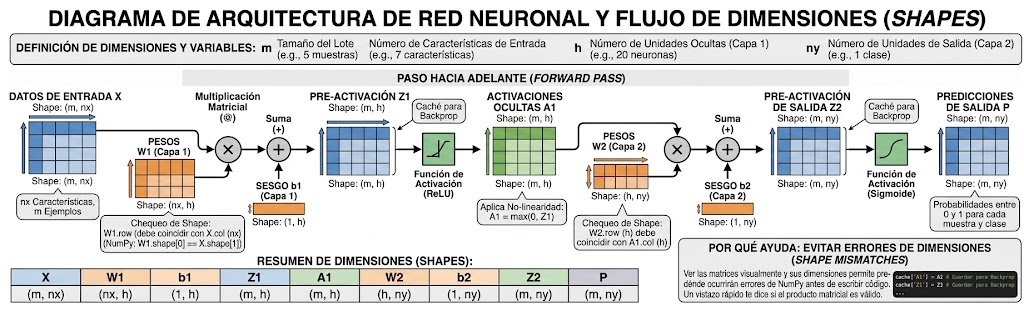

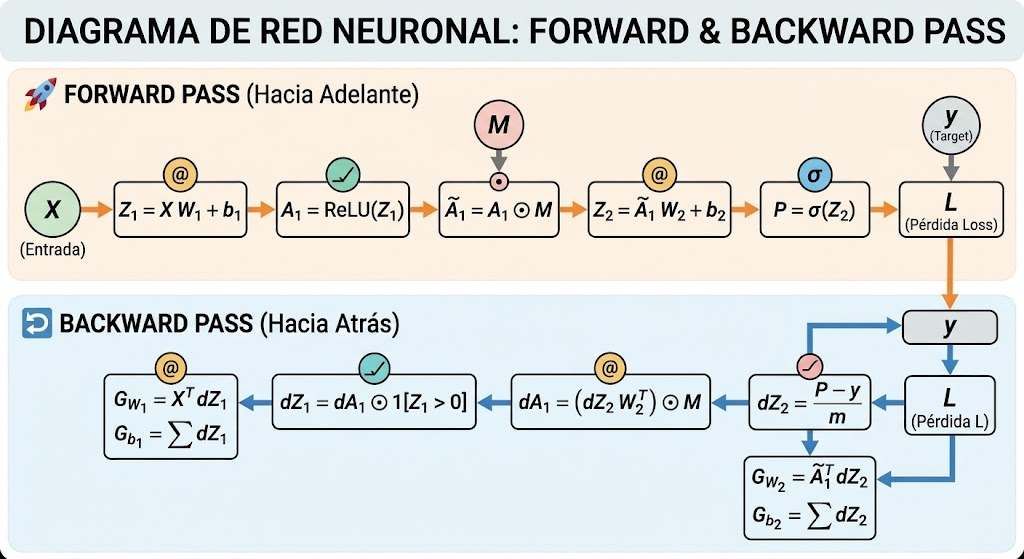

In [13]:
# ==============================================================================
# 1. IMPORTACIÓN DE LIBRERÍAS ESTÁNDAR Y CIENTÍFICAS
# ==============================================================================

import io, gzip, base64, hashlib, time, sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display



# ==============================================================================
# 2. CONTROL DEL FLUJO DE EJECUCIÓN (MECANISMO DEL CUADERNO)
# ==============================================================================
# Conjunto de datos (set) que almacena los números de ejercicios resueltos por el estudiante.
# Ej: SOLVED_EXERCISES = {1, 2} activa las funciones *_student de los ejercicios 1 y 2.
SOLVED_EXERCISES = set()  # e.g. {1, 2} after completing exercises 1 and 2
assert SOLVED_EXERCISES <= set(range(1, 7))


# Función conmutadora (Switch):
# Decide si usar la función del estudiante (student) o la solución de referencia (solution).
# Si el número de ejercicio está en SOLVED_EXERCISES -> Ejecuta código estudiante.
# Si la lista está vacía o el ejercicio no está ahí -> Ejecuta solución por defecto.
def choose(exercise, student, solution):
    return student if exercise in SOLVED_EXERCISES else solution

# ==============================================================================
# 3. CONFIGURACIÓN ESTÉTICA DE MATPLOTLIB Y VERIFICACIÓN DEL ENTORNO
# ==============================================================================
# Personalización global de los gráficos (definición de resolución, rejilla y tamaño de fuente)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True,
                     'grid.alpha': 0.2, 'font.size': 10})

# Auditoría de versiones: Imprime la versión activa del intérprete y las librerías
print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__, '| pandas:', pd.__version__,
      '| matplotlib:', matplotlib.__version__, '| scikit-learn:', sklearn.__version__)

# Muestra en consola qué implementaciones del estudiante están activas actualmente
print('Student implementations active:', sorted(SOLVED_EXERCISES))


Python: 3.13.16
NumPy: 2.1.3 | pandas: 2.2.3 | matplotlib: 3.10.0 | scikit-learn: 1.6.1
Student implementations active: []


## 1 · Data first: what may the network learn?

The original [R2D3 data](https://github.com/jadeyee/r2d3-part-1-data) are educational data, distributed under [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/). The embedded, unmodified CSV (see below) preserves its attribution and licence notice. The authors request that it **not be used to draw conclusions about either real-estate market** (this is the typical USA disclaimer to fend off lawsuits by people who don't understand how to use simple tools).

**Discuss:** Why is scaling before splitting a form of information leakage? What information is allowed to influence the fitted weights, hyperparameters, and final reported performance?

### 📊 1. Carga, Integridad y Limpieza de Datos (*Data Processing*)

#### Propósito de la Sección
Esta etapa se encarga de instanciar, auditar y limpiar los datos de entrada (*dataset R2D3*), garantizando la reproducibilidad sin necesidad de descargas externas y verificando la integridad matemática del arreglo tabular.

---

#### 💡 Concepto Teórico Clave: Fuga de Información (*Data Leakage*)
* **Riesgo:** Escalar las características antes de realizar la división (*split*) de datos contamina el conjunto de entrenamiento con parámetros estadísticos ($\min, \max, \mu, \sigma$) pertenecientes al conjunto de prueba.
* **Impacto:** Produce métricas de rendimiento sesgadas e irrealmente optimistas al sobreestimar la capacidad de generalización del modelo.
* **Buenas prácticas de separación de información:**
  1. **Pesos ($W, b$):** Influenciados **exclusivamente** por el conjunto de entrenamiento (*Train Set*).
  2. **Hiperparámetros:** Evaluados mediante el conjunto de validación (*Validation Set*).
  3. **Rendimiento Final:** Evaluado una sola vez en el conjunto de prueba (*Test Set*).

---

#### 🛠️ Operaciones de Limpieza Ejecutadas
* **Descompresión y Hash Check:** Descompresión en memoria via `gzip` + `base64` y validación criptográfica mediante SHA-256.
* **Deduplicación:** Eliminación de registros repetidos con `.drop_duplicates()` para evitar sesgos de sobremuestreo.
* **Auditoría Numérica:** Confirmación de etiquetas binarias $y \in \{0, 1\}$ en `in_sf` y ausencia de valores infinitos o `NaN` (`np.isfinite`).

### 🗂️ Arquitectura de Datos: ¿Cómo dividimos y por qué?

Para garantizar que una red neuronal aprenda de forma genuina y no caiga en el sobreajuste (*overfitting*), se divide el conjunto de datos total en tres subgrupos independientes:

1. **Conjunto de Entrenamiento (*Train Set*) Típicamente el 60% al 80% de los datos:**
    * **Que es?:** Es la porción masiva de datos con la que la red neuronal "aprende".
   * **Propósito:** Para ajustar los pesos ($W$) y sesgos ($b$) mediante las matemáticas que estamos programando (el forward pass y el backpropagation). El modelo ve tanto las características de las casas como sus respuestas correctas para encontrar patrones.
   * **Funcionamiento:** El modelo analiza las características y descubre los patrones lógicos subyacentes.



2. **Conjunto de Validación (*Validation Set*) Típicamente un 10% al 20%:**
  * **Que es?:** Un conjunto de datos intermedio que el modelo no usa para entrenar, sino para evaluarse mientras está aprendiendo.
   * **Propósito:** Evaluar el rendimiento intermedio y ajustar los hiperparámetros (arquitectura, tasa de aprendizaje). (como decidir cuántas neuronas ocultas poner, qué tasa de aprendizaje usar, o cuándo parar de entrenar para evitar el sobreajuste)
   * **Funcionamiento:** Permite calibrar el modelo durante su fase de desarrollo sin contaminar el entrenamiento.Funciona como un árbitro que nos dice si el modelo está generalizando bien o si se está memorizando los datos de entrenamiento.



3. **Conjunto de Prueba (*Test Set*) - Típicamente un 10% al 20%:**
   * **Que es?:** Un conjunto de datos completamente aislado y sagrado.
   * **Propósito:** Medición imparcial y final del desempeño del modelo. El modelo no puede ver estos datos bajo ninguna circunstancia hasta el final del proceso.
   * **Funcionamiento:** Contiene datos totalmente aislados que el modelo ve por primera vez al finalizar todo el proceso, simulando un entorno del mundo real.

### 🎓 Intuición y Arquitectura de Datos: La Analogía del Examen Final

Para comprender por qué dividimos nuestros datos en Machine Learning, podemos pensar en cómo se prepara un estudiante para un examen universitario muy exigente:

---

#### 1. La Analogía del Examen
* **Datos de Entrenamiento (*Train Set*):** Son todos los ejercicios y problemas resueltos que el profesor te da en el libro guía durante el semestre. Estudias de aquí para aprender los patrones y la lógica fundamental.
* **Datos de Validación (*Validation Set*):** Son los exámenes parciales o simulacros (*quizzes*) a mitad de ciclo. Sirven para ver tu progreso, calibrar cómo estás aprendiendo y ajustar tu forma de estudiar sobre la marcha.
* **Datos de Prueba (*Test Set*):** Es el **Examen Final**. Son preguntas completamente nuevas y jamás vistas en el libro ni en los simulacros. Es la única forma real de medir si de verdad entendiste la materia o si solo memorizaste.

---

#### 3. El Peligro del Sobreajuste (*Overfitting*)
Si un modelo carece de una separación estricta de datos y se le permite ver todo desde el inicio, ocurre el **sobreajuste**: el modelo actúa como un estudiante que memoriza de memoria los ejercicios exactos del libro guía, pero fracasa rotundamente en el examen final (*Test Set*) porque jamás desarrolló una capacidad real de generalización. Solo estaría respondiendo de "memoria" y ante algún dato nuevo el modelo dejaría de funcionar completamente porque en realidad no está "razonando".

In [14]:
# Original CSV snapshot retrieved 2026-10-13. Embedded for offline reproducibility.
# Source: https://raw.githubusercontent.com/jadeyee/r2d3-part-1-data/master/part_1_data.csv

# ==============================================================================
# 1. DESCOMPRESIÓN Y VERIFICACIÓN CRIPTOGRÁFICA DE DATOS EMBEBIDOS
# ==============================================================================

DATA_GZIP_BASE64 = 'H4sIAAAAAAACA51bXW9kt5F996+4QF42wB0Nvz/8ZhheIEDWu4mzG+TJ6JF6rIbl1qS75cHk16dOkVVka6RuYS2PIHVd8pL1cepUkfrD8rf73XG525w2x+1p+bw5LrePDw/b29P2bvn4eFi+W/5vd3zaPCx/2p8Oj3dPt6fd4345PS7/tbm93+23y5+3m8N+t/9l+Y/70+nTt+/ff/78+ebg7vzN0/GPN8ufTgvNv/l9s3vYfHjYLk/7u+1h2SzfH7ab0+737fL942+/Pe6Py3en02H34QnTv/vxcY+Pt4fb3ebh3U/3m8P2u4fdr9sl3BgsZHvYb/AgLevPu9vt/rjVt9/2eW/btDePh1/eP7Rnju8/fHm3v3133Lyned7T4pa/b5f7x0/bZXda7rcPn47Ll8en5dNhQ7u83S53u48ft4ft/sT6WTb0vi9H7GZ/t/zOWtn9a9P0sb293+/++bQ93iz//eMPy19/+Mv//vDT375d/udhS4pd7h6X/eNpeaIfT6JvKPG3DW1qs/9CSt/fPjwdd9DE5sPj04me2y4/bj8v/3g8/LqQIX7a7Jf/PGz2t7vj7eNCu3xYtsfT5rSlSQ6/bk/0ZjXlMzt+3p3ul4dup5VXstvzzm63K/24/Lbb390s37774zd/+Ga3//n4cf2wvTuuHzan+/XTgVSxfqHRP3942j2c1uM/P57apz9/2h5+5l+3D9vfWRPfmNWtdq21GmNWWxN9w0/0Af3AUvrK0eBDZ0xabbCFHvR1FbH1TWwrnrHRrMmVtZLU0ldyfWrj14gfXGxCiIPvQm9YWHJpr70oxLSB10RC14Q1miGsIqSRWJQ1xV+Tuq4KW6rMbJsu8EmTe/pyRuVpdY5f7dYgc4sii1tzCTQshzW+RWhdEGleC81to3Wr77qw1ooJypoqKSJWw2PZQCZiUU1qfabt4NchNt1AZBeLJduU8lBItnGYKJLA0eK8DA619DdDC4lXSGpo6rqJq0tifku/sIlNGi/3YfIOW2CmkqK6h7cmtuktbZlMsbpiXFsbKQe7EeejB3wiv/TZ5uGcFnPq/PwTfdINQuIkSsc3Xp31fmjd1nl09e1bEi+TtYuXmcnLXhl7bWXq38l1cQorqZhcwq5FtEb2pYVj1zRRoNc756KKnTNjYWR9zJ+nV4fuxE2rkR7yNGTIU3RDTt8Kyf0bxtsr40VuU44DMbBy6+Fx7k3yOVLimgFF9Lphs6hWSV2vEaCjYl07DbaBlOXDmkWxVY1GKw8tFoY7kuvLYIrRQG/O0IC5OLeq7ZXJh1rr5DHOOBofUmGregyPpW2sFPqgOYw4FKAneQ2FHmkuBsORyuL4lTi5IY5V3ZFiyPN7bFAxa1xHA069j0mBzRaBJ/gBb80TQGqURzOBAP+Uo3lJzNvLQII4YZ8mmLxmvCD7xAaFMxRxBoqHwl5cE9uT47vO8OIlyLPMnEWcfPcVWRceyOqGdY2Bk1vl90LI6QdDsVIalM2QEapwiqyltKwGjWjKE1WR7fG2MvuA1dBNoYOxEVTht9o+OFieOfkpJb74WpW+uBv13cur6ublsYSQJKLEPQ2WFEHIzoMFDXpUjOSUCxzA9YzZcFL9MtAqSJKRcBXL0iSmLAgO4XOTMw1IQgNcw2AoRIRRhImEASYOLZ7w4qguG3jR2bux4yxeRTkRWakG/NKFJU/Chu6VYp2lFKkKT7RNzxTAa0b6/4rddTHnS5FSIBEHWks4y0g+aq6mrE6WKXkWh0nM6ORncMtJPLM2PlXinM6yG6NrTng+v0gS6VMPelPLG+T+0sbCS++mbQREObmBYH4RN6C4SBkks+YhfWVjuSPfYF7kRIwexXf/ZLFiF8Rp9sALOq+XdV4vK7V+hZsIKICQA312EvFRKAQpK+IRnssq75vENmBTwfohH7MXgAUhpPOVBEI6qwwn4h0L74wgd9hERyOsYNVE6nfxDXKO60nr2FmRRMvAXgf3B8blUEYMJMmiyXK2AKKpsV8VMpvMg01SOg6kcF9TagollBcv7W/GL8Q5ySKsM9a4FCXEkwN0Qv/NCNyl5MCg70Sd7FR4iD7BaoCDLrgp/BT5Y+k5wdupCgsgFMrJcoAp/EwuBnVhOS06xIk9hJLPOBvkQqTZz4OmUg/r0NyeqPb0gHET6/OwqNf8E+jL+mAmru4xjXF9CdCurWZ6INRMPljcpL+XtSt5pviouTwrO2Kv4P+z0iv6JfHSHCick9QaRpUbuKD0A39iKd10NBZBXib8afjCYUq/Uv5iuCLziu7tzJeRayiS8qvygLIK+BWv2DZesW28YluRx7mIcqQAyrq2DHn1c5FlItFCw2B4zfRRTW/jmemhIV/nB17xjXjNNwQvirL+0NgNl6rwHOKMwgOZJtL7HC0gJDMFn9UimOIyITYTqLuyDCXHKL6wM8IN5zszz9riAA8wFN0+ho6UjcCakWFScxTTxM18qhxsyBDvR4Wvcp90uGFNkXlKHlB7SW7nNACiYxpDYyHHVBg1h0dqYs8TtUQ/pCFyiVpHRMeRf3wjI1QP1YaGjKejteBRmOMV5LmNKjE9L1PWLx4kysShtxff7vJXjSVvO7c3cCyBekVbslnDA6t8heTaIqIwrwCyOMMpURAREzLD2cNMpV6e2z/n0sSRwQ8L2VUTW3aDKycGIXQ1pJrRJEBBnoEhpNG2ZU4RacpeMJaDn2TZktMYcMwsQEzJPZSlay3Uyig0dLzU1LpfcmHQ90BAV7Qer6PstSbSZAn71aTarVy4LYjuDiXNIjuyz4QlNg5OxQCZeqr8giVQRa6vl+ZVC7448TBgFI4AGGc0smEi+EH7K9AjbZD0KCUNZwM3koUH4QTxslcmV/LTDdUIKVXTcLeJcmZx7F5AVKv1w6src6KVLLUYeVUmz6xz9zK0EpCFidAGycDHCyO9JJFqwqjgI7mG4uM1KQUq66PzUOBAIG1FK1KBGCC+oZTLHaMqjic+7RoDBifK/pqQo8EPE1nKQVQUNM/ifOAEUym/gdtGPwmFlEOIjYDElUvTjkQRZGLC6ZwK18ZzCyhO4ooyJk5eZ5OWA2EFjSEaXK6O1ko6lwGXKGYsN0PF61wxcw0FWCFG3+TsG7Z1ONG6jsTpMw1OMtbmEf+U3SoQME0LV/JU8SlKrGon/3DOz+OhsYCHQk8VpUig04oo/6OwN25QGKv5W+fP2bUq7NL7tZOjxN7lNRUkuOoncVDeD31yRxHRXp91TFtvCtM7S0pkangTGR5DHZ0EyqF2Crpox+QZnmqN8OK5BRVTKxCtszPQmDyABmcOfmKOVpECfJOrLIPjBq0+RwLFlkD6fHflC+IXrMolnpGmkHpU1SIt97UXlIhhdP+r+qtNwN9oJmZi43SYQhoPIOXY5nlR0Zp3tLTeSlG9yuEQrS5xDRhWKTec5iSsulZQACKm9ro44AHtYFP0OwdszuRO5hvbXhxHbZrBmhIzJtvYfqhT4erR7QpNyubO83EX2gmxYjl95qwKIzQibK6gQ7UJydFGMxNMjOyVyBxeVjUdtUSwU4tzBxZiJVKh4PjHcOxyfMt7izbFM6LbtMbhW6TDShRbpKxIxshNjNAO3ozzP4+2r3U1juFp2nKmGGhJoivTo+qKGncZNLJJu0JE2Qh7S+/P7MQqt5ohKkdXXhmORWVpyngpE+Siz9tMxZ2dqISIk1qhfOyejeXzLLQAMzqyyfeFT/2L3A4gmv9akVfFagQUAyqhopF9JzOJU2QErl3s9SiAxYSt6OwQ6shoUnBRnRKq1+YLIibYHyqn2gux6x2L/RT1LTY8k1sqZ3RnyhPRWUxMew1a6k0tVVXaPJ9eTzEhrkKVpi3NnOi0udKtSe+FtcaboWgKSMQAa/zqA61LWOeNwVo4E/SxyTGBiROQY/H4J95W5o2DshcTNLyq6pTIa3atkTgppY55LbpGVJWvQQKolJHW4UjECwUvrJ+whsggToRCGmI3YyhivtSwjh2VeUNkLW52RdWYUzmAGbUnn/D28WudR6M5mGNkUGibMqNvQZUGp4fAlmY/cXlaeGQmVOfgm08UiFKtfICsQCgt21KR3umRDKVIfGgP3fIiGRWiP4cMDkw09vlQpoqdyug7FjSKLU4GrFhi6kpSVUAISjCdzHPs5sYRamEydBKQTLYoq8+ESiWjUOpDo+bx0mtZUh+twHcYtIPhkFuiR51dR8lmSKddlBaVoDjgcLKvHIwTio13wM7BPtcIXw6gyCO4i1aNPBIDTtgYSONwMFkYoMaTGVEfxiQoqDkaeQrntNh6km1bq5c/QlMZpWiKKol4zdFUmuXaio5Uv1o1M0CmtNmre01XJXDkyw6S84v69LQj9L5L1pQV1bH56I+iLvc19+q8dRVI2bU7dfNan0ukEranHPQkCHgrv9XdIAQkGaIREypUZZvX40YDH+NnfcCCZmY04wQKUh7nVZGJuMPLnqmTxUj+FGSz2GilbdpBGxrU3vQkr5vGURl6fa7iSLArtObpLgPaFeDB3oudQ8F/8G40rE07sfRFw7XIaLA4AqhCRCLG6+LQ1j0dkjgYiv6xH9C7gct5umjhAuEIlJZ1eje173AmQuNdiy3emZoEtIisiaAuYaQNbSMA/1KAppyCc28bs8Gx55yENk2VeIHrkR+gsugJi97SX8u1fcC1InQ2mycQMAu+mY4lBY1xGTuHDd9PoCwdSh+bp+2C2meychBT6MEkQhmdTocTFlg5wY7a7UPvJ0LNjvBeU1wex/iWS2aahbEAvFdP8Q2KA0rQodgm5T5mKIOtR4cbCVZwhPFeFhY6m4lE52Lqe9KeCNTPRIyW1nwTZKoUPWvyhPUBICKJKE1HsRYMEGHXkZfZaXNc7s+gvspAR5JGzunSinFtepxUlf5eWnSaTg5twptRZI0t14kCWjAvijlxS21Aomhims8XLmRhY2rWLK0LgF/eJNXWKYomS+AZsDuf1Kc1QeJUDQcdAQHv61seCPxAqr0rU7gs4QsoqPJkfeLd3FkNsbV0gsLzuL8EEKN8U2ISOLkobsiftRWZ0MgAu4mGbQY8mO7C4CAp9uMaTfLKQUFX5BZeDm+SZgkBkTp4k0iLeyZFdy+H50YD88AtHty+qrLnuRDie09IbEQ5W8qibUXNtbj1V7hJgGaEL5Kqy8iI3MEBtwqpR4nAf7tTCFKO/p3mWuU2vacMopjNNSGS6biFx21+chQYJUclgmU6xOb7DqA2YozBAZg3cxuPeGq16ouK7iG3fmikrOYljLKoDRU4bB1BodJzlRP0klfQojtN9EzYyjij5luLQEoBaI199JtwlyrySfdVaVq5E1FGmYM0m/iQUNKlnc7WXfJYU2lbTuzBVVGa6R56CrT+zB4e+wm10gAsvNXlHYipDhiA6ND3iUhdtk45TeITrBphwv3pJFWcelJgJopWAVfn4kpOXcm0Xlr2CBxeP33pPVbDhNIwlU5Zq1s9M4LbIxGhaVWUNGr4Qt45J2kc2zOtDa3uFkmtYOOsu4tCO2cRVJDIjsm8QejPeC70hEuq1fO6R0EypUbm9gFnn7KlXEavmc954e1R+ZEyHLTSQkQnoiuM7A1EC9PN4IBDQkShsl2nb0cv3/O5t+/yBtcuTrnI5ZC4nlKKVCfCS1vxfMGQpQ1RU5huF4bEXQfUZVU8LnV/bw5RwHVqT2bIo8lJPODaH7caM+3Sqcmtn2rviKqM1Kd8BzinwznSY0Q25bdbrcv5nhbfYomocgcN66mKSFbh6z1pgJdcq2yhyLUgKiD7AmTz4UMsvcnjRsPN8q0cvn1OEMPY07Q+LgXQ3DiACpTGkmT44sZtK86R3A2UNw+uxXO39lZpxMSv474E3C0kZmI1y7rE2LjvA8Ib0aax5rqYlod1j5soqPX4ViQp3Hdre9WZR4uZB1MWrMrlbHCTu7fWayijjClpVIUcZoa77VrMqrcBfgpXllkJ7tmlclxUsFzxlsYAQsPPMrV6Em67EnH3TfXjumsrt5kxumymvkfROgrLR+EJDau4uufi1LomfBgRx4V3h4NOT6lHaZtkHDQycVIQce9KTB7KuMiK8ipzC63rbAY2azLCMLT6PnA1IbdX+PSZgiOhfyUUOI1eN7fsoinS+GLu7Qa7tnz9GHe7teJNcoiA0XyMmqQwxN6nS7CgLcEHaZrZEQFsB9P6+JqdcxyRaS16v5TimST2NDg1tzy4DqAtytyaRvgwGiVpza0bw07az9K4lInox6F7UBVy03SezZdGCyeapFWlc5MlPdpbCZ3+kQT10pSLjQJz+5jZRUNNRUW+54XeN59s56SwFiZmk2id7Ypq1a7QdPs4OUYXW8b8TrWL3jagN2fTn5hQvR0OeST5hP6tdKTG38402wDagpcSYhIig+P+XJB2lM+T0ckwPYMH5bJmvizgcGDv6igjx9+5AFWBa+TQtRWDZ5k4WY6DgjoySao5O10xwXImS5qIx+XaxG0e/nuipHzQjG0xW8RBYhVEHhwc4sz3tGafidMFPxvZX/iam1dCeWZPsiCn4qS4NJ004ngC14H4L07KV0UAt8fRouH+oxteaSdyRLYsLWAJS6Rbouct3IdCtwO1obfPu5ToYUbcLw9T6ccN/y6Hbbxtl1rDaKPrFgBdNda1XYf1Sj6FWgKB+ECHi2M/3FYDi9zRg3iCYdr8dbYHOke+WIQsNwBYS5nKZ+RAXyBbyc+7Bdlx/y6BVpUqmGSnisFFy+TVhatSrja0A4wslwM3E/zULIrSrG9/jGC5LalRpcVK4Bs1FPAef1txVRrOqhUw9Z7ytRsalEAB7gkHcRHGDL+s2g/wfEMRpzrlq+YKv5fWC9+YT04iEUz8yYnhb3xoac8aClRyjJzo8GdOifv10xyuhmdPcMNteiJZe667YvjdAhsaHEBR8heAsW+55ryxX7ipDzbYU40749DqOTnjSFJSaJ0aULgpFKIduflMiqhKCXDd+WvRG5yxB1W2rdw7wzP0QTyfckmDkZj2REWcjbhRQ09ozzbNh3HJCZO6LmaepcdpKJ8Sevl6XDX+DoovC6M2N2gHjpnjuO/BIQysEwLlnB1TdzoT42ArF8+slLwin3E/EB3p0Cu41zqql4/HrzPHs8SFBsZLiev17BGbjxa9NobMh8Ow0n3IzTfAGfdh7jRIxTPSYQNKiXZvMF09Fr6Uz/8N8PtDO5o9AAA='
raw_csv = gzip.decompress(base64.b64decode(DATA_GZIP_BASE64))
# Paso B: Verificación de integridad SHA-256 (Garantiza que los datos no se hayan alterado)
assert hashlib.sha256(raw_csv).hexdigest() == '93ba9c6461bb45b31cba03a879eea865c8c96541869631b674d1f4bf15bd367c'

# ==============================================================================
# 2. CARGA EN PANDAS Y LIMPIEZA DE ESTRUCTURA
# ==============================================================================
# Convertir los bytes descomprimidos en un buffer I/O y leerlo como DataFrame de Pandas
data_raw = pd.read_csv(io.BytesIO(raw_csv), comment='#')

# Eliminar filas duplicadas idénticas y reindexar de forma limpia
data = data_raw.drop_duplicates().reset_index(drop=True)

# ==============================================================================
# 3. ASSERTIONS (PRUEBAS DE INTEGRIDAD DE LOS DATOS)
# ==============================================================================
# Validar que la variable objetivo 'in_sf' contenga únicamente valores binarios {0, 1}
#Estos son los TARGETS
# 1 es SAN FRANCISCO
# 0 es NEW YORK

assert set(data['in_sf'].unique()) == {0, 1}

# Validar que ningún valor numérico en el dataset sea infinito (Inf) o nulo (NaN)
assert np.isfinite(data.to_numpy(dtype=float)).all()


# ==============================================================================
# 4. REPORTES DE SALIDA Y VISUALIZACIÓN INICIAL
# ==============================================================================
# Imprimir recuento de filas antes y después de eliminar duplicados
print(f'Rows: {len(data_raw)} original; {len(data)} after removing exact duplicates.')

display(data.head())
# you can give a numerical argument to `head`, indicating how many events you want to print from the beginning of the dataset
display(data.head(10))

# you can also print from the end, using `tail`
# Visualizar las últimas filas para verificar el cierre del dataset
display(data.tail())


Rows: 492 original; 459 after removing exact duplicates.


,in_sf,beds,bath,price,year_built,sqft,price_per_sqft,elevation
0,0,2.0,1.0,999000,1960,1000,999,10
1,0,2.0,2.0,2750000,2006,1418,1939,0
2,0,2.0,2.0,1350000,1900,2150,628,9
3,0,1.0,1.0,629000,1903,500,1258,9
4,0,0.0,1.0,439000,1930,500,878,10


,in_sf,beds,bath,price,year_built,sqft,price_per_sqft,elevation
0,0,2.0,1.0,999000,1960,1000,999,10
1,0,2.0,2.0,2750000,2006,1418,1939,0
2,0,2.0,2.0,1350000,1900,2150,628,9
3,0,1.0,1.0,629000,1903,500,1258,9
4,0,0.0,1.0,439000,1930,500,878,10
5,0,1.0,1.0,475000,1920,500,950,10
6,0,1.0,1.0,975000,1930,900,1083,10
7,0,1.0,1.0,975000,1930,900,1083,12
8,0,2.0,1.0,1895000,1921,1000,1895,12
9,0,3.0,3.0,2095000,1926,2200,952,4


,in_sf,beds,bath,price,year_built,sqft,price_per_sqft,elevation
454,1,0.0,1.0,539000,2000,709,760,5
455,1,4.0,4.0,3760000,1894,3085,1219,49
456,1,5.0,2.5,1800000,1890,3073,586,76
457,1,2.0,1.0,695000,1923,1045,665,106
458,1,3.0,2.0,1650000,1922,1483,1113,106


We remove exact duplicate rows before splitting, to prevent identical records from appearing on both sides of a split. This does not establish that every remaining row represents an independent property; no property identifier is supplied. We use orthogonal **60% train / 20% validation / 20% test** partitions.

When preprocessing the data with a `scaler`, remember to always fit the `scaler` only on training features. **Never** scale the labels.

The labels (targets) are the variable `in_sf`: **1 = San Francisco (positive class), 0 = New York**. In particle-physics analogy, these play the roles of signal and background, but here the rows here are houses, not collision events.


### 📌 Resumen: Preprocesamiento y Manejo de Datos

| Concepto | Detalle / Regla | ¿Por qué es importante? |
| :--- | :--- | :--- |
| **División de Datos** | **60%** *Train* / **20%** *Validation* / **20%** *Test* | Evita el sobreajuste (*overfitting*) y evalúa el modelo con datos independientes. |
| **Limpieza** | Eliminación de filas idénticas (*duplicates*) | Impide que la misma casa aparezca tanto en *train* como en *test*. |
| **Escalado de *Features*** | Ajustar (`fit`) el `scaler` **solo con el conjunto de entrenamiento** | Evita la fuga de información (*data leakage*) desde validación/test hacia el modelo. |
| **No escalar *Labels*** | **NUNCA** aplicar escalador a la variable `in_sf` | Mantener los valores binarios exactos (`0` = New York, `1` = San Francisco) es fundamental para la función de pérdida. |

### 🎯 2. La Variable Objetivo (*Target*) y el Propósito del Modelo

#### 🏙️ ¿Qué queremos lograr en este cuaderno?
El objetivo es entrenar una red neuronal capaz de resolver un **problema de clasificación binaria**: determinar la ubicación geográfica de una vivienda basándose en sus características intrínsecas.

---

#### 🏷️ Definición de *Features* vs. *Labels*
* **Features (Características de entrada):** Son los atributos numéricos de cada casa (precio, tamaño, etc.) que entran a la red a través de la capa de entrada ($D = 7$).
Como la salida es una probabilidad entre 0 y 1 (gracias a la función Sigmoid que programamos en el Ejercicio 2), la red nos dirá, por ejemplo: "Hay un 85% de probabilidad de que esta casa sea de San Francisco" ($0.85 \rightarrow 1$).
* **Labels / Targets (Etiquetas objetivo):** Representan la respuesta real y correcta que el modelo debe aprender a adivinar. Son las respuestas correctas que le damos a la red durante el entrenamiento para que sepa si acertó o falló (in_sf: 0 o 1).

---

#### 🔢 Significado de la Variable Objetivo (`in_sf`)
La columna `in_sf` define a qué ciudad pertenece cada registro del dataset:
* **`1` = San Francisco** (Clase positiva).
* **`0` = New York** (Clase negativa).

* **Advertencia técnica:** Aunque las *features* de entrada se normalizan o escalan para optimizar el entrenamiento, **los *labels* (`in_sf`) NUNCA deben ser escalados**; deben conservarse estrictamente como valores binarios `0` o `1` para que la función de pérdida evalúe correctamente el error de predicción.

In [15]:
# ==============================================================================
# 1. EXTRACCIÓN DE CARACTERÍSTICAS (X) Y ETIQUETAS (y)
# ==============================================================================
# Obtener los nombres de todas las columnas de entrada (excluyendo 'in_sf')
feature_names = data.drop(columns='in_sf').columns.tolist()

# Matriz de características X: Convierte las columnas seleccionadas en una matriz numérica (N muestras x D dimensiones)
X = data[feature_names].to_numpy(dtype=np.float64)

# Vector de etiquetas y: Extrae 'in_sf' y lo convierte en un vector columna bidimensional con reshape(-1, 1)
y = data['in_sf'].to_numpy(dtype=np.float64).reshape(-1, 1)


# ==============================================================================
# 2. PARTICIÓN ESTRATIFICADA DE DATOS (60% Train / 20% Val / 20% Test)
# ==============================================================================
# Crear un arreglo con los índices numéricos de todas las filas del dataset
indices = np.arange(len(data))

# Fase 1: Separar un 20% de datos exclusivos para prueba (test) y un 80% para desarrollo (dev)
# stratify=y.ravel() asegura que el balance 0/1 se mantenga equilibrado en ambas partes
idx_dev, idx_test = train_test_split(indices, test_size=0.20, stratify=y.ravel(), random_state=42)


# Fase 2: Dividir el 80% de desarrollo en entrenamiento (60% del total) y validación (20% del total)
#STRATIFY - Asegura que las casas de NewYork o SanFrancisco se distribuyan uniformemente entre los 3 conjutnos
idx_train, idx_val = train_test_split(idx_dev, test_size=0.25,
                                    stratify=y[idx_dev].ravel(), random_state=43)


# Verificación de seguridad matemática: Asegura que no haya cruce o solapamiento de índices entre los conjuntos
assert not (set(idx_train) & set(idx_val) or set(idx_train) & set(idx_test)
            or set(idx_val) & set(idx_test))


# ==============================================================================
# 3. ESCALADO SEGURO DE CARACTERÍSTICAS (MIN-MAX SCALING)
# ==============================================================================
# Inicializar el MinMaxScaler y AJUSTARLO (.fit)
#EXCLUSIVAMENTE con el conjunto de entrenamiento train (Previene Data Leakage)
scaler = MinMaxScaler().fit(X[idx_train])

# Transformar de forma independiente los tres conjuntos utilizando los parámetros aprendidos del entrenamiento
X_train, X_val, X_test = [scaler.transform(X[i]) for i in (idx_train, idx_val, idx_test)]
y_train, y_val, y_test = [y[i] for i in (idx_train, idx_val, idx_test)]


# Extraer el número de muestras (N) y el número de características (D = 7) del set de entrenamiento
N, D = X_train.shape


# ==============================================================================
# 4. REPORTES DE AUDITORÍA Y ESTADÍSTICAS DEL DATASET
# ==============================================================================
# Imprimir los nombres de las 7 características de entrada
print('Features:', feature_names)

# Imprimir el tamaño de cada partición y cuántas casas pertenecen a San Francisco (SF) vs Nueva York (NY)
for name, labels in [('train', y_train), ('validation', y_val), ('test', y_test)]:
    print(f'{name:10s}: {len(labels):3d} rows, SF={int(labels.sum())}, NY={int((1-labels).sum())}')

# Calcular y mostrar la precisión si adivinaramos siempre la clase mayoritaria (Baseline de control)
print('Training majority-class accuracy:', max(y_train.mean(), 1-y_train.mean()))



Features: ['beds', 'bath', 'price', 'year_built', 'sqft', 'price_per_sqft', 'elevation']
train     : 275 rows, SF=148, NY=127
validation:  92 rows, SF=49, NY=43
test      :  92 rows, SF=50, NY=42
Training majority-class accuracy: 0.5381818181818182


### 📊 Resumen y Auditoría de los Datos Procesados

* **Atributos de Entrada ($D = 7$):** `['beds', 'bath', 'price', 'year_built', 'sqft', 'price_per_sqft', 'elevation']`
* **Distribución de Particiones:**
  * **Train:** 275 filas (148 de San Francisco / 127 de Nueva York).
  * **Validation:** 92 filas (49 de San Francisco / 43 de Nueva York).
  * **Test:** 92 filas (50 de San Francisco / 42 de Nueva York).
  ---

#### ⚖️ Estratificación de las Particiones
Mediante el uso de `stratify=y` en las divisiones de scikit-learn, nos aseguramos de que los conjuntos de **Train**, **Validation** y **Test** mantengan una proporción equilibrada y representativa de ambas clases (1,0) (SanFrancisco,New York) en todo momento, previniendo sesgos de muestreo.

* **Línea Base (*Majority-Class Accuracy* ~53.8%):** Precisión obtenida por un modelo trivial que adivina siempre la clase más frecuente. Nuestra red neuronal debe superar significativamente este valor para validar su aprendizaje.

### 📌 Resumen: División, Estratificación y Escalado de Datos

| Paso / Componente | Acción que realiza | Detalle / Resultado |
| :--- | :--- | :--- |
| **Separación $X$ e $y$** | Divide las características de la columna objetivo (`in_sf`) y convierte los datos a matrices NumPy de tipo `float64`[cite: 6]. | `feature_names` guarda los predictores y $y$ almacena las etiquetas en forma de vector columna[cite: 6]. |
| **División Estratificada** | Emplea `train_test_split` para separar el dataset en proporciones de entrenamiento, validación y prueba manteniendo el balance de clases[cite: 6]. | Genera **275 filas** para entrenamiento, **92** para validación y **92** para prueba[cite: 6]. |
| **Validación de Índices** | Usa un `assert` lógico para confirmar que los conjuntos de índices son totalmente disjuntos[cite: 6]. | Garantiza que ninguna casa aparezca repetida o compartida entre particiones[cite: 3, 6]. |
| **Escalado (`MinMaxScaler`)** | Ajusta (`fit`) el escalador **exclusivamente con los datos de entrenamiento** y transforma las tres particiones[cite: 3, 6]. | Normaliza las características numéricas de forma segura, evitando fugas de información (*data leakage*) hacia test o validación[cite: 3, 6]. |
| **Resumen y Métricas** | Imprime los nombres de las características, tamaños de cada partición, conteo de clases (SF/NY) y la precisión de la clase mayoritaria[cite: 6]. | Permite verificar rápidamente las dimensiones y el balance base del conjunto (`0.538` en train)[cite: 6]. |

### 📐 Estructura Matricial y Dimensiones de los Datos ($X$ e $y$)

- FEATURES X
- LABELS Y


Para que las operaciones de álgebra lineal y las multiplicaciones matriciales de la red neuronal funcionen correctamente, transformamos el conjunto de datos tabular en estructuras de NumPy con formas (*shapes*) bien definidas:

#### 1. Matriz de Características - FEATURES ($X$) de dimensión $(N \times 7)$
Contiene todas las variables predictoras de las viviendas, donde cada fila es una casa y cada columna una característica numérica:
$$X = \begin{pmatrix} x_{1, \text{beds}} & x_{1, \text{bath}} & x_{1, \text{price}} & \dots & x_{1, \text{elevation}} \\ x_{2, \text{beds}} & x_{2, \text{bath}} & x_{2, \text{price}} & \dots & x_{2, \text{elevation}} \\ \vdots & \vdots & \vdots & \ddots & \vdots \\ x_{N, \text{beds}} & x_{N, \text{bath}} & x_{N, \text{price}} & \dots & x_{N, \text{elevation}} \end{pmatrix}$$
* **Features ($D=7$):** `['beds', 'bath', 'price', 'year_built', 'sqft', 'price_per_sqft', 'elevation']`.

#### 2. Vector Columna de Etiquetas - LABELS ($y$) de dimensión $(N \times 1)$
Se utiliza `.reshape(-1, 1)` para transformar las etiquetas objetivo en un vector columna bidimensional:
$$y = \begin{pmatrix} y_1 \\ y_2 \\ \vdots \\ y_N \end{pmatrix} = \begin{pmatrix} 1 \text{ (San Francisco)} \\ 0 \text{ (New York)} \\ \vdots \\ 1 \text{ (San Francisco)} \end{pmatrix}$$



## 2 · A network is a collection of matrices

We will use one hidden layer with **20 ReLU units**, followed by one sigmoid output (to output something that we can interpret as probability of belonging to a class). We will also learn the bias parameters (the order-zero terms in the perceptron equation).
This small network is enough to expose every calculation; deeper networks simply repeat the same operations, and you would not learn anything new.

For a batch of $m$ houses, with $d$ input features and $h=20$ hidden units:

| Quantity | Shape | Meaning |
| :--- | :--- | :--- |
| $X$ | $(m, d)$ | one row per house |
| $W_1, b_1$ | $(d, h), (1, h)$ | hidden weights and biases |
| $Z_1 = X W_1 + b_1$ | $(m, h)$ | hidden preactivations |
| $A_1 = \text{ReLU}(Z_1)$ | $(m, h)$ | hidden activations |
| $W_2, b_2$ | $(h, 1), (1, 1)$ | output weights and bias |
| $Z_2 = A_1 W_2 + b_2$ | $(m, 1)$ | output logits |
| $P = \sigma(Z_2)$ | $(m, 1)$ | score estimating $P(\text{SF} \mid X)$ |

Matrix multiplication `@` contracts the shared dimension. A bias broadcasts across rows. A sigmoid score lies in [0, 1], but it is not automatically a calibrated probability.



### 📐 Arquitectura Matricial de la Red Neuronal

Para un lote de $m$ viviendas, con $d$ características de entrada y $h = 20$ unidades ocultas, la red neuronal opera mediante transformaciones matriciales sucesivas. A continuación se detallan las dimensiones y el significado de cada componente:

| Variable / Operación | Forma (*Shape*) | Significado y Descripción del Componente |
| :--- | :--- | :--- |
| **$X$** | $(m, d)$ | **Matriz de entrada:** Cada fila representa una vivienda y cada columna una característica numérica ($d = 7$). |
| **$W_1, b_1$** | $(d, h), (1, h)$ | **Pesos y sesgos de la capa oculta:** Parámetros ajustables que conectan las $d$ características con las $h = 20$ neuronas ocultas. |
| **$Z_1 = X W_1 + b_1$** | $(m, h)$ | **Preactivaciones (Logits ocultos):** Combinación lineal resultante del producto matricial entre las entradas y los pesos, sumando el sesgo. |
| **$A_1 = \text{ReLU}(Z_1)$** | $(m, h)$ | **Activaciones ocultas:** Aplica la función no lineal ReLU sobre $Z_1$, apagando valores negativos y dejando pasar los positivos. |
| **$W_2, b_2$** | $(h, 1), (1, 1)$ | **Pesos y sesgos de salida:** Parámetros que colapsan las $h$ neuronas ocultas hacia la única neurona de salida. |
| **$Z_2 = A_1 W_2 + b_2$** | $(m, 1)$ | **Logits finales de salida:** Puntuaciones globales brutas antes de aplicar la función de activación final. |
| **$P = \sigma(Z_2)$** | $(m, 1)$ | **Puntuación de probabilidad:** Aplica la función sigmoide ($\sigma$) para transformar los logits en una estimación de probabilidad $P(\text{SF} \mid X)$. |

---

#### 🔍 Notas Clave sobre el Flujo Matricial:
* **Multiplicación Matricial (`@`):** Contrae las dimensiones compartidas durante el paso de información entre capas (ej. una matriz de $(m, d)$ multiplicada por $(d, h)$ produce $(m, h)$).
* **Propagación del Sesgo (*Broadcasting*):** Los vectores de sesgo ($b_1, b_2$) se expanden automáticamente a lo largo de todas las filas del lote de datos.
* **Interpretación de la Salida:** La puntuación final $P$ se encuentra acotada estrictamente en el intervalo $[0, 1]$, representando qué tan probable es que una casa pertenezca a San Francisco.

### 📐 Guía Visual Paso a Paso: Dimensiones y Transformaciones Matriciales

Para dominar el funcionamiento interno de una red neuronal, es fundamental comprender cómo viajan, se multiplican y transforman los datos a través de matrices.

Primero, definimos las **tres dimensiones clave** que guiarán todo el flujo de cálculo:
* **$m$ (Tamaño del lote / *Batch Size*):** Número de viviendas que procesamos simultáneamente en una sola pasada.
* **$d$ (Dimensiones / Características):** Número de atributos de entrada por cada casa ($d = 7$: camas, baños, precio, año, metros cuadrados, precio por metro cuadrado y elevación).
* **$h$ (Unidades ocultas):** Número de neuronas en la capa oculta ($h = 20$).

---

### 🚀 Paso 1: De la Entrada ($X$) a la Primera Capa Oculta ($Z_1$)

* **Fórmula matemática:**
  $$Z_1 = X W_1 + b_1$$

* **Componentes y Dimensiones:**
  * **Matriz de Entrada $X$:** Forma **$(m, d)$**. Cada fila representa una vivienda y cada columna una de las 7 características.
  * **Matriz de Pesos $W_1$:** Forma **$(d, h) = (7, 20)$**. Conecta cada característica de entrada con cada neurona oculta.
  * **Vector de Sesgo $b_1$:** Forma **$(1, h) = (1, 20)$**.

* **Visualización de la Multiplicación Matricial:**
  $$\underbrace{\begin{pmatrix}
  x_{1,1} & x_{1,2} & \dots & x_{1,7} \\
  x_{2,1} & x_{2,2} & \dots & x_{2,7} \\
  \vdots & \vdots & \ddots & \vdots \\
  x_{m,1} & x_{m,2} & \dots & x_{m,7}
  \end{pmatrix}}_{(m, \mathbf{7})}
  \times
  \underbrace{\begin{pmatrix}
  w_{1,1} & w_{1,2} & \dots & w_{1,20} \\
  w_{2,1} & w_{2,2} & \dots & w_{2,20} \\
  \vdots & \vdots & \ddots & \vdots \\
  w_{7,1} & w_{7,2} & \dots & w_{7,20}
  \end{pmatrix}}_{(\mathbf{7}, h)}
  +
  \underbrace{\begin{pmatrix} b_1 & b_2 & \dots & b_{20} \end{pmatrix}}_{(1, h)}
  =
  \underbrace{\begin{pmatrix}
  z_{1,1} & z_{1,2} & \dots & z_{1,20} \\
  z_{2,1} & z_{2,2} & \dots & z_{2,20} \\
  \vdots & \vdots & \ddots & \vdots \\
  z_{m,1} & z_{m,2} & \dots & z_{m,20}
  \end{pmatrix}}_{(m, h) \text{[cite: 16]}}$$

> 💡 **Nota de contracción:** El **7** interno se multiplica (filas por columnas) y se contrae, dando como resultado una nueva matriz de preactivaciones $Z_1$ con forma **$(m, h) = (m, 20)$**. El sesgo $b_1$ se expande (*broadcasting*) de manera automática a lo largo de todas las filas del lote.

---
### ⚡ Paso 2: Aplicando la Función de Activación ReLU ($A_1$)

* **Fórmula matemática:**
  $$A_1 = \text{ReLU}(Z_1)$$

* **Componentes y Dimensiones:**
  * Toma la matriz $Z_1$ con forma **$(m, 20)$** y aplica la operación no lineal elemento a elemento (*element-wise*).
  * Si un valor en $Z_1$ es negativo, la ReLU lo convierte en $0$. Si es positivo, lo deja intacto.
  * **La forma geométrica no cambia:** La matriz resultante $A_1$ mantiene exactamente la misma dimensión **$(m, 20)$**.

* **Visualización de la Transformación:**
  $$\underbrace{\begin{pmatrix}
  z_{1,1} & z_{1,2} & \dots & z_{1,20} \\
  z_{2,1} & z_{2,2} & \dots & z_{2,20}
  \end{pmatrix}}_{(m, h) \text{[cite: 16]}}
  \xrightarrow{\text{ReLU}}
  \underbrace{\begin{pmatrix}
  \max(0, z_{1,1}) & \max(0, z_{1,2}) & \dots & \max(0, z_{1,20}) \\
  \max(0, z_{2,1}) & \max(0, z_{2,2}) & \dots & \max(0, z_{2,20})
  \end{pmatrix}}_{(m, h) \text{ (con ceros en valores negativos)} \text{}}$$

---
### 🎯 Paso 3: Los Logits Finales de Salida ($Z_2$)

* **Fórmula matemática:**
  $$Z_2 = A_1 W_2 + b_2$$

* **Componentes y Dimensiones:**
  * **Matriz $A_1$ (Activaciones ocultas):** Posee forma **$(m, 20)$**.
  * **Matriz de Pesos de Salida $W_2$:** Posee forma **$(h, 1) = (20, 1)$**. Contrae las 20 neuronas ocultas hacia la única neurona de salida.
  * **Sesgo $b_2$:** Forma **$(1, 1)$**.

* **Visualización de la Multiplicación Matricial:**
  $$\underbrace{\begin{pmatrix}
  a_{1,1} & a_{1,2} & \dots & a_{1,20} \\
  a_{2,1} & a_{2,2} & \dots & a_{2,20} \\
  \vdots & \vdots & \ddots & \vdots \\
  a_{m,1} & a_{m,2} & \dots & a_{m,20}
  \end{pmatrix}}_{(m, \mathbf{20})}
  \times
  \underbrace{\begin{pmatrix}
  w'_{1} \\
  w'_{2} \\
  \vdots \\
  w'_{20}
  \end{pmatrix}}_{(\mathbf{20}, 1) \text{}}
  +
  \underbrace{\begin{pmatrix} b_2 \end{pmatrix}}_{(1, 1) \text{}}
  =
  \underbrace{\begin{pmatrix}
  z'_{1} \\
  z'_{2} \\
  \vdots \\
  z'_{m}
  \end{pmatrix}}_{(m, 1) \text{}}$$

> 💡 **Nota de contracción:** El **20** interno se contrae, transformando las 20 características de la capa oculta en un único valor bruto (logit) por cada vivienda. La matriz resultante $Z_2$ adopta la forma **$(m, 1)$**.

### Paso 4: La Activación Sigmoide Final ($P$)

* **Fórmula matemática:**
  $$P = \sigma(Z_2)$$

* **Componentes y Dimensiones:**
  * Aplica la función matemática de la sigmoide de manera individual a cada elemento del vector columna $Z_2$
  * Transforma esos números reales (logits) en una puntuación matemática acotada estrictamente en el intervalo $[0, 1]$.
  * **Forma final:** Conserva las dimensiones de vector columna $(m, 1)$, donde cada fila representa la probabilidad estimada $P(\text{SF} \mid X)$ de que esa vivienda pertenezca a San Francisco.

* **Visualización de la Transformación:**
  $$\underbrace{\begin{pmatrix}
  z'_{1} \\
  z'_{2} \\
  \vdots \\
  z'_{m}
  \end{pmatrix}}_{(m, 1)}
  \xrightarrow{\text{Sigmoide } \sigma}
  \underbrace{\begin{pmatrix}
  p_1 \\
  p_2 \\
  \vdots \\
  p_m
  \end{pmatrix}}_{(m, 1) \text{ (Valores decimales entre 0 y 1)}}$$

### 🎯 Concepto Clave: ¿Qué son los **Logits**?

* **Definición:** Los *logits* son las puntuaciones brutas y sin procesar que genera una capa de la red neuronal **antes** de aplicarles cualquier función de activación (como la Sigmoide).
* **Origen matemático:** Representan el resultado directo de la combinación lineal, es decir, la suma ponderada de las entradas multiplicadas por los pesos más el sesgo ($XW + b$).
* **Rango de valores:** Al ser valores libres, pueden ser números reales de cualquier tamaño, desde $-\infty$ hasta $+\infty$.
* **Significado:** Por sí solos, los *logits* no son probabilidades ni suman $1$. Un valor de *logit* más alto simplemente indica una mayor "fuerza" o preferencia de la red hacia esa opción antes de ser comprimidos por la activación.

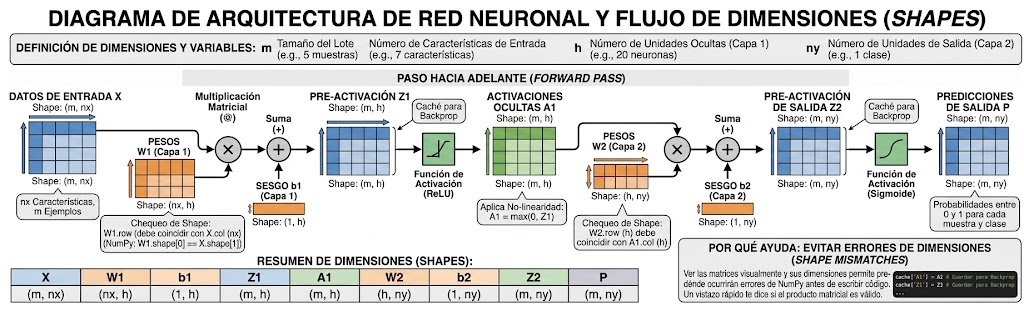


### Exercise 1: Activation functions
**Predict:** What are sigmoid(0), sigmoid′(0), ReLU(−2), and ReLU′(2)?

**Code:** Complete two lines. `sigmoid_student` uses `exp(-abs(z))` to avoid overflow. Its branching logic is supplied. Implement the derivative **with respect to the input logit**, using `s = sigmoid_student(z)`. In `relu_student`, keep positive values and zero the rest. We define the ReLU derivative at zero to be zero.

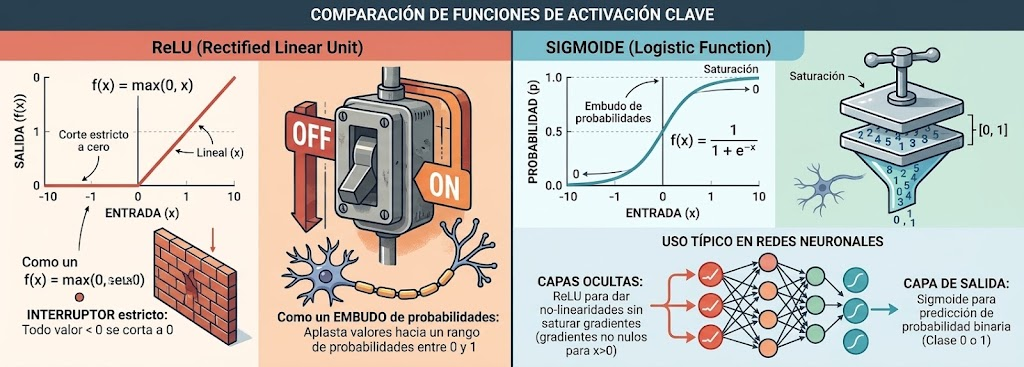

In [16]:
#FUNDAMENTAL ENTENDER : "z" son los valores de entrada


def sigmoid_student(z):    #Define la función que recibirá un valor o
                          #un conjunto de valores llamados z
                          # Z es la ENTRADA. Es el exponente del euler de la sigmoide

    z = np.asarray(z, dtype=float)  #Convierte la entrada z en un arreglo de NumPy
                            #y hace que sus datos sean de tipo decimal (float).

    t = np.exp(-np.abs(z))  #Calcula una variable temporal t utilizando el valor
                            #absoluto negativo de z para evitar el OVERFLOW
                            #Cuando se haga e^z
                            #Basicamente t= e^-z (es un cambio de variable)



    return np.where(z >= 0, 1/(1+t), t/(1+t))  #Función condicional de NumPy
                                              # "np.where" permite elegir 2 caminos
                                              #Si (z >= 0): Aplica la fórmula estándar adaptada 1 / (1 + t)
                                              #------------
                                              #Si z es negativo: Utiliza una versión reescrita
                                              #de la sigmoide (t / (1 + t))
                                              #tiene una precisión numérica perfecta
                                              #y se evita el OVERFLOW con numero muy grandes



def sigmoid_derivative_student(z):
    s = sigmoid_student(z)   #Calculo la sigmoide llamando a la funcion anterior
    return s * (1 - s) # Derivative in terms of s, sacada de las diapositivas de la clase


def relu_student(z):
    return np.maximum(z, 0)  # Elementwise maximum of z and zero

    #Basicamente RELU hace
    #Numeros Negativos---> Relu=0
    #Cero ----> Relu = 0
    #Numero positivos X ---> Relu= X (el mismo numero)

    #np.maximun con (z,0) hace exactamente eso, se comporta como la RELU


### 📈 Guía Explicativa: Implementación Robusta de la Sigmoide (`sigmoid_student`)

La fórmula matemática clásica de la función sigmoide es:
$$g(z) = \frac{1}{1 + e^{-z}}$$


Sin embargo, programarla de forma directa puede provocar fallos informáticos por desbordamiento de memoria (*overflow*) cuando los números son muy grandes. A continuación se detalla cómo funciona el código optimizado integrando tus notas clave:

---

### 💻 Desglose del Código Paso a Paso

```python
def sigmoid_student(z):
    # 💡 FUNDAMENTAL ENTENDER: "z" son los valores de entrada (logits).
    # Z es el exponente del número de Euler (e) en la fórmula de la sigmoide.
    
    # 1. Conversión de seguridad
    z = np.asarray(z, dtype=float)  # Convierte la entrada z en un arreglo de NumPy
                                    # y hace que sus datos sean de tipo decimal (float).
    
    # 2. Truco de optimización (Cambio de variable para evitar OVERFLOW)
    t = np.exp(-np.abs(z))          # Calcula una variable temporal 't' utilizando el valor
                                    # absoluto negativo de z (básicamente: t = e^-z).
                                    # Esto garantiza que el exponente nunca sea un número positivo gigante.
    
    # 3. Selección de caminos mediante bifurcación condicional
    return np.where(z >= 0, 1/(1+t), t/(1+t))  # "np.where" permite elegir 2 caminos:
                                              # - Si (z >= 0): Aplica la fórmula estándar adaptada 1 / (1 + t).
                                              # - Si (z es negativo): Utiliza una versión reescrita t / (1 + t).
                                              # Esto logra una precisión numérica perfecta
                                              # y evita por completo el OVERFLOW con números muy grandes.

### 📐 Resumen: Derivada de la Sigmoide (`sigmoid_derivative_student`)

| Concepto | Detalle / Fórmula | ¿Por qué es útil? |
| :--- | :--- | :--- |
| **Fórmula Teórica** | $g'(z) = s \cdot (1 - s)$ <br>*(donde $s = g(z)$)* | La derivada de la función sigmoide se puede expresar de forma elegante directamente en función de su propia salida ($s$). |
| **Implementación** | `return s * (1 - s)` | Es altamente eficiente computacionalmente porque reutiliza la variable `s` ya calculada previamente, evitando operaciones exponenciales adicionales. |

### 🚪 Guía Explicativa: Función ReLU (`relu_student`)

La función **ReLU** (*Rectified Linear Unit* o Unidad Lineal Rectificada) actúa como un filtro simple y eficiente para las neuronas:

| Comportamiento de la ReLU | Condición Matemática | Efecto en el Valor |
| :--- | :--- | :--- |
| **Bloqueo (*Negativos*)** | $z < 0$ | Aplasta cualquier número negativo convirtiéndolo estrictamente en **$0$**. |
| **Paso libre (*Positivos*)** | $z \ge 0$ | Mantiene el valor original intacto, comportándose como una línea recta ($y = z$). |

---

### 💻 Implementación en Código

```python
def relu_student(z):
    # Calcula el máximo elemento a elemento entre la entrada z y cero.
    # Si z es negativo, retorna 0. Si z es positivo, retorna z.
    return np.maximum(z, 0)

### ⚡ Concepto Clave: ¿Por qué es indispensable la No-Linealidad (ReLU)?

Imagina que las operaciones base de una red neuronal (multiplicar la matriz de entradas por los pesos y sumar el sesgo: $XW + b$) son puramente **lineales**.

| Dimensión / Enfoque | Solo Operaciones Lineales ($XW + b$) | Con la función ReLU |
| :--- | :--- | :--- |
| **Geometría** | Solo pueden trazar **líneas rectas**, planos o hiperplanos planos. | Permite **doblar, curvar y segmentar** el espacio de datos. |
| **Efecto de apilar capas** | Apilar 10 capas lineales seguidas equivale matemáticamente a **una sola** capa. ¡No ganas complejidad! | Apilar capas con ReLU permite modelar formas complejas como **parábolas**, curvas y patrones multidimensionales. |

---

### 🔍 La Magia del "Doblez"
* **El problema de la linealidad pura:** Si una red solo tuviera operaciones lineales, por más profunda o gigante que fuera, su resultado final siempre sería una simple línea recta combinada. No podría separar un mercado inmobiliario complejo ni resolver problemas reales.
* **El papel de la ReLU:** Al actuar como un filtro que aplasta los negativos a $0$ y deja pasar los positivos ($y = z$), la ReLU introduce un **quiebre o doblez** en las líneas.
* **Poder de representación:** Al combinar los "dobleces" de múltiples neuronas ocultas (como nuestros $h = 20$ nodos), la red neuronal se convierte en un aproximador universal capaz de construir formas y fronteras de decisión sumamente intrincadas.

In [17]:
# Reference solution 1. Read only after trying the student cell.
def sigmoid(z):
    z = np.asarray(z, dtype=float)
    t = np.exp(-np.abs(z))
    return np.where(z >= 0, 1/(1+t), t/(1+t))

def sigmoid_derivative_solution(z):
    s = sigmoid(z)
    return s * (1-s)

def relu_solution(z):
    return np.maximum(0, z)


Now that you have coded your `*_student` functions, it's time to plot them!

Note that, in case you don't implement the student functions, the `choose` command below will run the reference solution (the only one with a return value).

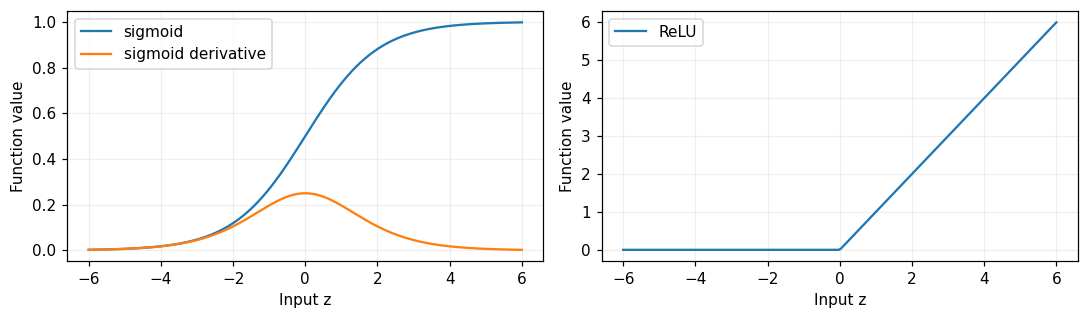

In [18]:
#Elige entre las 2 implementaciones, la del collab o la que yo hice
sigmoid_derivative = choose(1, sigmoid_derivative_student, sigmoid_derivative_solution)
relu = choose(1, relu_student, relu_solution)

#El choose 1:
#Es elegir mi propia implementación (sigmoid_derivative_student, relu_student)

#----------------
#SON PRUEBAS AUTOMATICAS (TEST)
#para comprobar que las funciones que implemente, funcionen bien
#Primero estan los valores de prueba, y luego los valores solucion

#Para -1000 la sigmoide vale 0
#Para 0, la sigmoide da exactamente 0.5

np.testing.assert_allclose(sigmoid(np.array([-1000, 0, 1000])), [0, 0.5, 1])


#Recuerda la fórmula: s *(1 - s)
# Sigmoid derivative 0.5 = 0.25
#¡El test verifica que dé justamente eso!
np.testing.assert_allclose(sigmoid_derivative(np.array([0.])), [0.25])


# 3. Prueba de la función ReLU: evalúa el arreglo [-2., 0., 2.]
#    - El -2 es negativo -> la ReLU lo aplasta a 0.
#    - El 0 se queda en 0.
#    - El 2 es positivo -> la ReLU lo deja pasar intacto (2).
#    Resultado esperado: [0, 0, 2]

np.testing.assert_array_equal(relu(np.array([-2., 0., 2.])), [0, 0, 2])


#----------------SECCION DE GRAFICOS------------
#Linspace crea puntos EQUIDISTANTES (a la misma distancia pue)
#Entre más puntos allá, hay mayor resolucion
z = np.linspace(-6, 6, 200)

#Crea un arreglo de 200 números ordenados y separados a la misma distancia,
#desde el -6 hasta el 6

#Esto servirá como el eje X (nuestros valores de entrada o LOGITS)
#para poder dibujar las curvas de forma suave y continua en las gráficas.

#Matplotlib
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
#Usando la librería matplotlib crea una ventana con 1 fila y 2 columnas de gráficos
#con un tamaño total de 10 pulgadas de ancho por 3 de alto.

#La variable axes guarda ambas gráficas en una lista:
#axes[0] será el panel izquierdo y axes[1] el panel derecho.

#------El trazado de las líneas en cada panel-----
# axes[0] es izquierdo y axes[1] es derecho.

#Izquierdo
axes[0].plot(z, sigmoid(z), label='sigmoid')
#Dibuja la curva de la sigmoide evaluando todos los puntos de z (la entrada o LOGITS)
axes[0].plot(z, sigmoid_derivative(z), label='sigmoid derivative')
#Dibuja la curva correspondiente a la derivada de la sigmoide con los LOGITS


#Derecho
axes[1].plot(z, relu(z), label='ReLU')
#Dibuja en el panel derecho (axes[1]) la curva de la función ReLU


for ax in axes:   #Bucle que recorre las dos gráficas una por una
    ax.set(xlabel='Input z', ylabel='Function value'); ax.legend()
#Le coloca nombre a los ejes: Input z en el eje horizontal y Function value en el eje vertical
#ax.legend(): Activa y muestra las pequeñas cajitas de leyenda en las esquinas de los gráficos

plt.tight_layout(); plt.show()

#plt.tight_layout(): Ordena y ajusta automáticamente los espacios entre los dos gráficos
#plt.show(): Renderiza y muestra la imagen final completa

### 📊 Resumen Maestro: Funciones de Activación y sus Derivadas

| Función | Expresión Matemática | ¿Para qué sirve? | ¿Dónde se usa en la red? | Característica visual / clave |
| :--- | :--- | :--- | :--- | :--- |
| **Sigmoide** | $g(z) = \frac{1}{1 + e^{-z}}$ | Comprime cualquier número real en un rango estricto de **0 a 1**, ideal para interpretarlo como una probabilidad. | Típicamente en la **capa de salida** para problemas de clasificación binaria. | Forma de "S" estirada; se aplana (*satura*) en los extremos $-\infty$ e $+\infty$. |
| **Derivada de la Sigmoide** | $g'(z) = s(1 - s)$ | Mide la pendiente o sensibilidad de la neurona (cuánto cambia la salida ante variaciones en la entrada). | Durante el **entrenamiento (*Backpropagation*)** para propagar el error y actualizar pesos. | **¡Tiene forma de campana!** (Explicada en detalle abajo). |
| **ReLU** | $f(z) = \max(0, z)$ | Actúa como un filtro estricto que anula los valores negativos a cero y deja pasar los positivos intactos. | En las **capas ocultas** (como nuestros 20 nodos) para introducir **no-linealidad** y doblar el espacio de datos. | Forma de "palo de hockey" o línea plana que asciende a partir del cero. |

---

### 🔔 ¿Por qué la derivada de la sigmoide tiene forma de "Campana"?

La curva naranja de la derivada se asemeja a una campana (simétrica con una joroba central) debido al comportamiento de la pendiente de la sigmoide en los diferentes puntos del eje de entradas ($z$):

1. **En los extremos (valores muy negativos o muy positivos):** La función sigmoide se vuelve completamente horizontal ($y \approx 0$ o $y \approx 1$). Como la curva no está inclinada, **su pendiente es cero**. Por eso la curva de la derivada toca el piso (vale $0$) tanto a la izquierda como a la derecha.
2. **En el centro ($z = 0$):** Es el punto donde la sigmoide cruza el centro y sube con la mayor inclinación posible. Su pendiente alcanza su valor máximo absoluto, que es exactamente **$0.25$**.
3. **El resultado visual:** Al partir de cero en los extremos, subir suavemente hasta un pico máximo de $0.25$ en el centro y volver a descender de forma simétrica, dibuja de manera natural una joroba con forma de campana (muy similar a una distribución gaussiana, aunque matemáticamente provenga de multiplicar $s \cdot (1 - s)$).

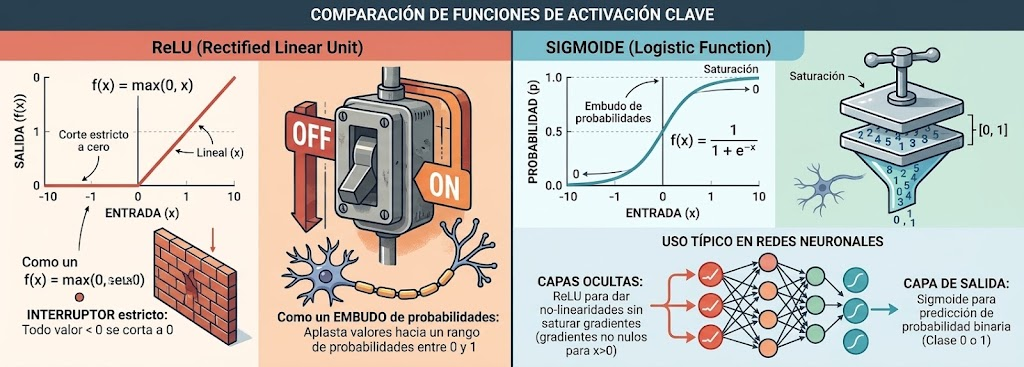

#EXPLICACIONES TEORICAS DE LAS REDES NEURONALES - OPCIONAL (SI QUIERES PUEDE MINIMIZAR)

### 📐 Sección 1: De la Ecuación de la Recta a la Combinación Lineal y el **Logit**

Para entender qué ocurre dentro de una red neuronal, debemos partir de la base matemática más sencilla que aprendemos en la escuela: la **ecuación de la recta**:

$$y = m x + b$$

* **$x$**: Es tu variable de entrada (el dato).
* **$m$**: Es la pendiente, la cual determina la inclinación de la recta.
* **$b$**: Es el intercepto o **sesgo (*bias*)**, que se encarga de desplazar la recta hacia arriba, hacia abajo, a la izquierda o a la derecha. Si el sesgo no existiera ($b = 0$), todas las fronteras de decisión de una neurona estarían obligadas a pasar estrictamente por el punto de origen $(0,0)$ del plano. El sesgo le otorga a la neurona libertad para activarse cuando lo necesite, funcionando como un nivel base de entusiasmo o timidez.

#### ¿Qué pasa cuando tenemos múltiples características? (Suma Ponderada)
Cuando evaluamos un objeto del mundo real (por ejemplo, una casa con características como el tamaño, número de baños, antigüedad, etc.), la entrada ya no es un solo número $x$, sino un conjunto de características $(x_1, x_2, \dots, x_k)$. La ecuación se extiende a una **combinación lineal**:

$$z = (w_1 x_1 + w_2 x_2 + \dots + w_k x_k) + b$$

* **Los pesos ($w$)**: Funcionan como las "perillas de importancia" o pendientes independientes para cada característica. Si evaluamos casas, una neurona puede darle un peso muy alto al número de baños y un peso negativo a la antigüedad.
* **Los pesos no se suman de forma aislada**: Primero **se multiplican** cada característica por su respectivo peso y luego **se acumulan (suman en conjunto)** junto con el sesgo.
* **El Logit ($z$)**: El resultado numérico bruto de esta gran suma ponderada antes de pasar por cualquier función de activación se conoce como **logit**. Es una puntuación libre que va desde $-\infty$ hasta $+\infty$.

### 🧮 Sección 2: La Mecánica de las "Perillas" y la Inicialización de Pesos

* **¿Por qué NUNCA debemos inicializar los pesos en ceros?** Si inicializaramos todos los pesos en cero, todas las neuronas ocultas harían exactamente los mismos cálculos matemáticos, recibirían los mismos gradientes y actualizarían sus valores de idéntica forma. Tendrías 20 neuronas ocultas, pero actuarían como si fuera una sola.
* **Pesos aleatorios y asimétricos**: Al asignarles valores iniciales aleatorios, rompemos la simetría matemática desde el primer segundo. Esto permite que cada neurona comience analizando un aspecto o perspectiva diferente de los datos, repartiéndose el trabajo de manera eficiente.

### 📐 Bloque 3: Controlando la Magnitud: Desviación Estándar, Inicialización de He y de la Salida

Cuando inicializamos los pesos de manera aleatoria, no podemos elegir números al azar sin control. La **desviación estándar** actúa como la perilla que define qué tan grandes o dispersos son esos números iniciales, evitando dos catástrofes: que las señales exploten hacia el infinito o que mueran reduciéndose a cero al atravesar muchas capas.

* **Inicialización de He ($\sqrt{2/d}$):** Está diseñada específicamente para capas ocultas que utilizan la función de activación **ReLU**. Como la ReLU destruye la mitad de la información al anular todos los valores negativos (volviéndolos ceros), esta fórmula calcula matemáticamente el tamaño perfecto de los números aleatorios para compensar ese "apagón" y mantener la fuerza de la señal estable a lo largo de la red.
* **Inicialización de la capa de salida ($\sqrt{1/h}$):** Utiliza el número de unidades ocultas ($h$, por ejemplo, 20) para controlar y escalar adecuadamente la magnitud de la señal antes de entregar la predicción final.

### ➕ Bloque 4: De la Combinación Lineal a la Creación de **Logits**

Toda la maquinaria inicial de una neurona opera mediante una **combinación lineal**.

* **¿Cómo se combinan las características?** Imagina que analizamos una casa con múltiples características (precio, número de habitaciones, metros cuadrados, etc.). Cada característica se multiplica por su peso correspondiente (su importancia asignada por la neurona) y al final todos esos productos se acumulan (suman) junto con el sesgo.
* **Definición de Logit:** El resultado numérico bruto de esa gran suma ponderada antes de pasar por cualquier función de activación (como la Sigmoide o la ReLU) se le conoce como **logit**. Es una puntuación libre, sin restricciones, que va desde $-\infty$ hasta $+\infty$ y representa cuánta "preferencia" o fuerza tiene la red hacia una conclusión antes de ser interpretada.

### ⚡ Sección 3: El Álgebra Lineal en Acción: Multiplicación de Matrices y Hardware (GPUs)

En lugar de calcular las operaciones de una neurona y una muestra a la vez (lo cual sería extremadamente lento), las redes neuronales modernas procesan todo mediante **matrices y vectores**, lo que permite aprovechar al máximo la potencia de cálculo en paralelo de las tarjetas gráficas (**GPUs** y **FPGAs**).

Observando las dimensiones clave de las matrices en la arquitectura de red:

#### 🔹 Caso A: Procesamiento de una sola muestra ($m = 1$)
Imagina que evalúas **una sola casa** ($m=1$) con $k$ características:
* **Entrada (*Input*):** Es un vector (una fila) de tamaño $1 \times k$:
  $$\text{Input} = \begin{bmatrix} x_1 & x_2 & \dots & x_k \end{bmatrix}$$
* **Pesos (*Weights*):** Es una matriz de tamaño $k \times n$ (donde $n$ es el número de neuronas ocultas). Cada **columna** de esta matriz representa los pesos de una neurona distinta:
  $$\text{Weights} = \begin{bmatrix} w_{1,1} & w_{1,2} & \dots & w_{1,n} \\ w_{2,1} & w_{2,2} & \dots & w_{2,n} \\ \vdots & \vdots & \ddots & \vdots \\ w_{k,1} & w_{k,2} & \dots & w_{k,n} \end{bmatrix}$$
* **Salida (*Output*):** Al multiplicar la entrada por los pesos ($\text{Input} \times \text{Weights}$), obtienes un vector de tamaño $1 \times n$. ¡Cada número de ese vector es el **logit** que calculó una de las $n$ neuronas para esa muestra!

#### 🔹 Caso B: Procesamiento por lotes (*Batches*, $m$ muestras)
En la práctica, nunca le pasas una sola muestra a la red; procesas **un lote de $m$ muestras** al mismo tiempo para ganar velocidad:
* **Matriz A (Entradas - $m \times k$):** Tiene $m$ filas (una por cada muestra del lote) y $k$ columnas (las características de cada una).
* **Matriz B (Pesos - $k \times n$):** Es nuestra matriz de pesos fija con $k$ filas y $n$ columnas.
* **Matriz C (Resultado - $m \times n$):** El producto matricial ($\text{A} \times \text{B}$) genera una gran tabla de resultados donde cada **fila** es una muestra distinta y cada **columna** representa una neurona oculta, albergando todos los *logits* calculados en paralelo.

### 🔄 Sección 4: El Ciclo de Vida: Del *Forward Pass* al *Backpropagation*

Una vez entendida la combinación lineal y las matrices, el funcionamiento global de la red opera en un ciclo continuo:

1. **El viaje de ida (*Forward Pass*):**
   * Los datos entran a la red en forma de matrices.
   * Se multiplican por los pesos y se les suma el sesgo ($XW + b$), generando los *logits*.
   * Los *logits* atraviesan la función **ReLU**, la cual actúa como un filtro que destruye los valores negativos (volviéndolos cero) y deja pasar los positivos intactos. Esto introduce **no-linealidad**, permitiendo que la red doble el espacio y modele formas complejas (como parábolas) en lugar de limitarse a meras líneas rectas.
   * Al llegar al final, la red emite una predicción.
2. **El cálculo del error:**
   * Se compara la predicción de la red contra la etiqueta real para medir la magnitud del fallo.
3. **El viaje de vuelta (*Backpropagation*):**
   * La red viaja desde la última capa hacia atrás propagando derivadas mediante la **regla de la cadena sobre matrices y vectores**.
   * Su objetivo es asignar una "puntuación de responsabilidad" a cada peso y neurona para identificar quién contribuyó más al error.
4. **La actualización:**
   * Con base en las derivadas calculadas, los pesos se ajustan ligeramente en la dirección opuesta al error, haciendo que la red sea cada vez más precisa en las siguientes iteraciones.

# CONTINUANDO CON LOS PARAMETROS

### Initialize the parameters

Now we have to initialize the network weights. For the hidden weights, we will use a standard deviation of $\sqrt{2/d}$, , appropriate to ReLU (He initialization); the output weights use √(1/h). Biases start at zero. Random, asymmetric weights allow hidden units to learn different features. Never initialize every weight to zero.

**Check:** How many trainable parameters are there? Calculate it! Don't forget to include in the calculation both bias vectors (hint: bias vectors increase by one the size of the input vector to each layer).



"bias vectors increase by one the size of the input vector to each layer" (los vectores de sesgo aumentan en uno el tamaño del vector de entrada de cada capa). **RECORDAR QUE TENEMOS 3 CAPAS**

Esto significa que, para cualquier capa, en lugar de calcular por separado las multiplicaciones de los pesos y la suma de los sesgos, puedes usar esta regla práctica. Forma original : XW + B
                        : (Parametros * Pesos) + Sesgo

### 🧮 Cálculo de los Parámetros Entrenables Capa por Capa

Para calcular el número total de parámetros de la red, utilizamos la regla práctica que considera el tamaño de la entrada más el sesgo de cada capa:

$$\text{Parámetros de una capa} = (\text{Tamaño de la Entrada} + 1) \times \text{Número de Neuronas de la Capa}$$

---

#### 1. Capa Oculta (*Hidden Layer*)
* **Tamaño de la entrada ($d$):** 7 características provenientes de los datos de entrada.
* **Número de neuronas:** 20 unidades ocultas.
* **Cálculo:** $(7 + 1) \times 20 = 8 \times 20 = \mathbf{160}$ parámetros.
  * *(Desglose: $7 \times 20 = 140$ correspondientes a la matriz de pesos $W_1$ + $1 \times 20 = 20$ correspondientes al vector de sesgos $b_1$)*.
 **Tengo 7 parametros por cada neurona y tengo 20 neuronas. Y cada neurona tiene un valor de sesgo que equivale a +1 parametro**
---

#### 2. Capa de Salida (*Output Layer*)
* **Tamaño de la entrada:** Recibe las 20 salidas de la capa oculta anterior.
* **Número de neuronas:** 1 sola neurona de salida.
* **Cálculo:** $(20 + 1) \times 1 = 21 \times 1 = \mathbf{21}$ parámetros.
  * *(Desglose: $20 \times 1 = 20$ correspondientes a la matriz de pesos $W_2$ + $1 \times 1 = 1$ correspondiente al sesgo final $b_2$)*.
  X(20) W(1) + B (1)

  -20 es la entrada X

  -Como solo se conecta a 1 neurona final W=1
  
  -Sesgo tambien por lo mismo =1

---

#### 3. Suma Total de la Red
Sumamos los parámetros calculados de ambas capas para obtener el resultado global:

$$160 \text{ (Capa Oculta)} + 21 \text{ (Capa de Salida)} = \mathbf{181} \text{ parámetros entrenables}$$

In [19]:
def initialize(n_inputs, n_hidden=20, seed=0):

#"initialize" es la función que empaqueta y crea todos los pesos y sesgos iniciales de nuestra red neuronal.
#Recibe el número de entradas (n_inputs), las neuronas ocultas (n_hidden=20) y una semilla aleatoria (seed=0).

    rng = np.random.default_rng(seed)
#"np.random" Crea un generador de números aleatorios moderno y seguro en NumPy.
#Usar una semilla (seed) garantiza que los números aleatorios sean exactamente
#los mismos cada vez que ejecutes el código.


    return {'W1': rng.normal(0, np.sqrt(2/n_inputs), (n_inputs, n_hidden)),
            'b1': np.zeros((1, n_hidden)),
            'W2': rng.normal(0, np.sqrt(1/n_hidden), (n_hidden, 1)),
            'b2': np.zeros((1, 1))}

#"W1" - Crea la matriz de pesos de la primera capa (oculta) con dimensiones
#de entrada por neuronas ocultas (n_inputs, n_hidden).
#Utiliza la DISTRIBUCION NORMAL rng.normal con la desviación estándar de He raiz(2/n)
#Aqui usamos la desviacion para las neuronas que usan el RELU (las ocultas)

#"b1" - Crea el vector de sesgos para la capa oculta, inicializado completamente en
#ceros y con forma (1, n_hidden).

#'W2' - Crea la matriz de pesos de la capa de salida con dimensiones (n_hidden, 1),
# usando la desviación estándar sqrt(1 /n_hidden)
#Aqui usamos la desviacion estandar para la ULTIMA Y UNICA NEURONA DE SALIDA

#'b2': np.zeros((1, 1)): Crea el sesgo final de la única neurona de salida.


#------------------------------------------------------------------

#copy_params: Una función de utilidad para clonar los parámetros sin modificar los originales
def copy_params(params):
    return {key: value.copy() for key, value in params.items()}

#-------------------------MAIN---------------------------------------------
initial_params = initialize(D, seed=7)
# Llama a "initialize" usando D = 7 (lo que significa que nuestras casas
# u objetos de entrada tienen 7 características o columnas).

print({key: value.shape for key, value in initial_params.items()})
##Imprime el tamaño (shape) de cada matriz, dando como resultado:
#{'W1': (7, 20), 'b1': (1, 20), 'W2': (20, 1), 'b2': (1, 1)}.

print('Parameters:', sum(value.size for value in initial_params.values()))

#Cuenta y suma todos los números individuales contenidos dentro de esas matrices
# y vectores, arrojando el total de 181 parámetros entrenables.


{'W1': (7, 20), 'b1': (1, 20), 'W2': (20, 1), 'b2': (1, 1)}
Parameters: 181


<details>
<summary>Worked answer — open after discussing</summary>

There are d×h + h + h×1 + 1 parameters. With seven features and 20 hidden units, this is 181. Biases shift activation thresholds without requiring a constant feature column.

d×h + h + h×1 + 1
7x20 + 20 + 20x1 + 1 = 181 PARAMETROS

</details>

### 🧠 ¿Qué es un Parámetro en una Red Neuronal?
Los parámetros son los valores internos de la red (**pesos $W$ y sesgos $b$**) que el modelo modifica y optimiza automáticamente durante el proceso de entrenamiento para aprender a clasificar correctamente las viviendas.

---

### 📐 Desglose de la Fórmula Analítica
La cantidad total de parámetros de nuestra red se compone sumando los pesos y sesgos de cada una de sus capas:

$$\underbrace{d \times h}_{\text{Pesos Capa 1 } (W_1)} + \underbrace{h}_{\text{Sesgos Capa 1 } (b_1)} + \underbrace{h \times 1}_{\text{Pesos Capa 2 } (W_2)} + \underbrace{1}_{\text{Sesgo Capa 2 } (b_2)}$$

* **$d \times h$**: Conexiones sinápticas entre las $d$ características de entrada y las $h$ neuronas ocultas.
* **$+ h$**: Un valor de sesgo independiente para cada una de las $h$ neuronas de la capa oculta.
* **$+ h \times 1$**: Conexiones desde las $h$ neuronas ocultas hacia la única neurona de salida.
* **$+ 1$**: El sesgo final de la neurona de salida.

---

### ⚙️ Sustitución con los Valores Numéricos Reales
Reemplazando con las dimensiones de nuestro cuaderno ($d = 7$ características de entrada y $h = 20$ neuronas ocultas):

$$\underbrace{7 \times 20}_{140} + \underbrace{20}_{20} + \underbrace{20 \times 1}_{20} + \underbrace{1}_{1} = \mathbf{181 \text{ parámetros entrenables}}$$

### 🧱 Arquitectura y Parámetros de la Red: Inicialización, Variables y Sesgos

---

#### 2. ¿Por qué los Pesos NUNCA pueden ser 0 pero los Sesgos SÍ pueden empezar en 0?
* **Los Pesos ($\neq 0$):** Deben ser aleatorios y asimétricos. Si inicializaras todos los pesos en cero, cada neurona calcularía exactamente lo mismo, recibiría los mismos gradientes y aprendería idéntico; actuarían como una sola neurona. La aleatoriedad rompe esta simetría para que cada neurona se especialice.
* **Los Sesgos ($= 0$):** Empiezan en ceros porque los pesos aleatorios ya se encargaron por completo de romper la simetría al arrancar. El sesgo solo actúa como un punto de partida neutral que se desplazará dinámicamente conforme la red comience a aprender los errores.

### Exercise 2: the forward pass (propagate the inputs to the predictions)

**Code:** First propagate `Xb` to `Z1`, apply `relu`, then propagate `A1` to `Z2` and apply `sigmoid`. Preserve the 2D shapes, even for a single house. Return a cache (i.e. don't erase the intermediate arrays, return them together with the rest of the forward output): backpropagation will need these intermediate arrays.

**Predict:** Why must `W1` have shape `(D, 20)` rather than `(20, D)` under our row-per-house convention?


### 🚀 Ejercicio 2: El *Forward Pass* (Propagación hacia Adelante)

El objetivo de este ejercicio es programar el viaje de ida de los datos desde la capa de entrada hasta la capa de salida para generar las predicciones de la red.

---

#### 1. Instrucciones de Implementación
Siguiendo las indicaciones del ejercicio, debemos realizar los siguientes pasos de forma secuencial preservando las formas en 2D (incluso cuando evaluamos una sola casa):
* **Propagar a `Z1`:** Multiplicamos la entrada de datos (`Xb`) por la matriz de pesos de la primera capa (`W1`) y le sumamos el sesgo (`b1`) para calcular los *logits* intermedios de la capa oculta.
* **Aplicar la función `relu`:** Tomamos esos *logits* `Z1` y les aplicamos `relu` para obtener la matriz de activaciones ocultas `A1`.
* **Propagar a `Z2`:** Tomamos las activaciones `A1`, las multiplicamos por la matriz de pesos de salida (`W2`) y le sumamos el sesgo final (`b2`) para obtener los *logits* de salida `Z2`.
* **Aplicar la función `sigmoid`:** Pasamos `Z2` a través de la función `sigmoid` para comprimir la salida final entre 0 y 1.
* **Retornar el `cache`:** Es un requisito obligatorio **no borrar ni omitir los arreglos intermedios** (`Xb`, `Z1`, `A1`, `Z2`), sino empaquetarlos en un diccionario llamado `cache` junto con la salida final. El algoritmo de *backpropagation* (el viaje de vuelta para entrenar la red) necesitará estrictamente estos valores guardados para calcular las derivadas.

---

#### 2. Respuesta a la Pregunta de Predicción (*Predict*)
> *"Why must `W1` have shape `(D, 20)` rather than `(20, D)` under our row-per-house-convention?"*
> *(¿Por qué `W1` debe tener la forma `(D, 20)` en lugar de `(20, D)` bajo nuestra convención de una fila por casa?)*

* **La convención de filas por casa:** Bajo nuestra estructura matricial, cada **fila** de la matriz de entrada representa una muestra distinta (una casa) y cada **columna** representa una característica (un total de $D$ características)(m x D)

* **La regla de oro del álgebra lineal:** Para que la multiplicación de matrices entre la entrada y los pesos (`Entrada × W1`) sea matemáticamente válida, el número de **columnas** de la matriz de entrada debe coincidir exactamente con el número de **filas** de la matriz de pesos.
* Como los datos de entrada tienen $D$ columnas, la matriz `W1` **necesita tener $D$ filas** para recibir correctamente esa información. A su vez, como queremos proyectar esas características hacia 20 neuronas ocultas, las columnas de `W1` deben ser 20.

* Por esta razón, la forma de `W1` debe ser obligatoriamente **`(D, 20)`** y nunca al revés (`(20, D)`), ya que de lo contrario las dimensiones colapsarían y Python arrojaría un error de multiplicación matricial.

In [20]:
def forward_core_student(Xb, params):
    #Logits iniciales - Valor bruto antes de la RELU
    #Viene de multiplicar Entradas * Pesos + Sesgo
    Z1 = n_inputs * W1 + b1  # Matrix multiply, then add hidden bias


   #A los Logits iniciales aplicar la RELU para covertir los valores de la Hidden Layer
    A1 = relu_student(Z1)  # Hidden activation

    #Calcular ahora los LOGITS de Salida
    Z2 = A1 * W2 + b2   # Propagate to output logit, including bias

    #Calcular las probabilidad usando la SIGMOIDE
    P = sigmoid_student(Z2)   # Output probability

    return P, {'X': Xb, 'Z1': Z1, 'A1': A1, 'A1_used': A1,
               'Z2': Z2, 'mask': np.ones_like(A1)}


### 🔍 ¿Qué pequeños detalles hay que ajustar en mi código (INTENTO DE HACERLO) ?

1. **Los pesos y sesgos viven dentro de `params`**:
   En lugar de usar variables sueltas como `W1` o `b1`, debes extraerlos del diccionario `params` que recibe tu función (por ejemplo: `params['W1']`, `params['b1']`, `params['W2']`, `params['b2']`), y tu entrada es `Xb`.

2. **Multiplicación de matrices (`*` vs `@`)**:
   En Python, el asterisco (`*`) realiza una multiplicación **elemento a elemento** (multiplica celda por celda). Sin embargo, como vimos en las matrices y las diapositivas, para calcular las neuronas necesitamos una **multiplicación de matrices** real. Para eso se utiliza el operador `@` (o `np.matmul`).
   * *Incorrecto:* `Xb * W1`
   * *Correcto:* `Xb @ params['W1']`

3. **Las llaves del diccionario `cache`**:
   El cuaderno suele esperar nombres específicos para el caché (como `'Xb'`, `'Z1'`, `'A1'`, `'Z2'`) para que el algoritmo de *backpropagation* pueda encontrarlos después sin errores.

### Paso 1
* **Fórmula matemática:**
  $$Z_1 = X W_1 + b_1$$

### Paso 2
* **Fórmula matemática:**
  $$A_1 = \text{ReLU}(Z_1)$$

### Paso 3
* **Fórmula matemática:**
  $$Z_2 = A_1 W_2 + b_2$$
### Paso 4
* **Fórmula matemática:**
  $$P = \sigma(Z_2)$$


In [21]:
# Reference solution 2. Read only after trying the student cell.

#--------Entradas de la funcion------
#Xb : Es la entrada a la red neuronal
# params: Es un diccionario que tiene los valores de W1,b1,W2,b2


def forward_core_solution(Xb, params):

    #Logits iniciales - Valor bruto antes de la RELU
    #Viene de multiplicar Entradas(Xb) * Pesos + Sesgo
    Z1 = Xb @ params['W1'] + params['b1']

 #A los Logits iniciales aplicar la RELU para covertir los valores de la Hidden Layer
    A1 = relu(Z1)


#Calcular ahora los LOGITS de Salida
    Z2 = A1 @ params['W2'] + params['b2']

 #Calcular las probabilidad usando la SIGMOIDE
    P = sigmoid(Z2)   # Output probability

#
    # CACHÉ DE VALORES INTERMEDIOS
    # ==========================================
    # ¿Por qué guardamos esto?
    # Durante el "Forward Pass" (viaje de ida) calculamos y almacenamos
    # estos arreglos intermedios. No debemos borrarlos, ya que son
    # estrictamente necesarios para el "Backpropagation" (viaje de vuelta).

    # Cuando la red empiece a corregir sus errores hacia atrás, usará
    # estos valores guardados (Z1, A1, Z2, etc.) para calcular las derivadas
    # mediante la regla de la cadena y actualizar los pesos correctamente.

#Devuelvo todos los valores calculados en "cache"
#Tiene 2 retornos
# P -Valor de la Probabilidad
# Matriz de Cache

    return P, {'X': Xb, 'Z1': Z1, 'A1': A1, 'A1_used': A1,
               'Z2': Z2, 'mask': np.ones_like(A1)}

#----------Elmementos que se van a usar------------------
# Xb - la entrada original
# Z1 - los logits de la capa oculta
# A1 - las activaciones de la ReLU
# A1_used - Respaldo de activaciones para la retropropagación
# Z2 - los logits finales de salida
# Máscara para la derivada de la ReLU


#QUE ES LA MASCARA?
#La máscara es un mapa o plantilla (un arreglo de ceros y unos) que guarda esa memoria:

#Marca con un 1 (o True) los lugares donde la neurona estaba encendida y dejó pasar señal.
#Marca con un 0 (o False) los lugares donde la ReLU apagó la neurona.

#El algoritmo de backpropagation (el viaje de vuelta) puede usar esta máscara
#como un filtro rápido para multiplicar las derivadas y asegurar que las neuronas
#"apagadas" no aprendan errores falsos donde no había información activa.



#---------------- MAIN SEGUIR AQUI -------------------------------

# Selecciona automáticamente entre la función del estudiante y la solución oficial
forward_core = choose(2, forward_core_student, forward_core_solution)

# Ejecuta el forward pass utilizando un
# minilote de 5 casas del conjunto de entrenamiento

#2 variables para guardar los 2 retornos de la funcion
P0, cache0 = forward_core(X_train[:5], initial_params)

# Valida que la forma (shape) de la salida sea (5, 1)
# y la de la capa oculta Z1 sea (5, 20)
assert P0.shape == (5, 1) and cache0['Z1'].shape == (5, 20)

# Valida que no existan valores NaN/infinitos
# y que todas las probabilidades estén acotadas entre 0 y 1
assert np.isfinite(P0).all() and ((P0 >= 0) & (P0 <= 1)).all()


# ==============================================================================
# PRUEBAS TOY CON MODELO MINIATURA
# ==============================================================================

# Independent hand-calculable example, including nonzero biases.
# Ejemplo de control en miniatura (toy example) con matrices fijas
# y sesgos distintos de cero
toy = {'W1': np.array([[1., -1.], [2., 1.]]), 'b1': np.array([[0.5, 0.]]),
       'W2': np.array([[2.], [-1.]]), 'b2': np.array([[0.25]])}

# Ejecuta la propagación hacia adelante con el modelo miniatura
ptoy, ctoy = forward_core(np.array([[1., 2.]]), toy)

# Comprueba mediante tolerancias numéricas estrictas
# que los cálculos intermedios y finales sean exactos

#En este caso ya sabemos cual es la respuesta correcta, queremos ver si la
# red neuronal  puede calcular esos valores
np.testing.assert_allclose(ctoy['Z1'], [[5.5, 1.]])
np.testing.assert_allclose(ctoy['Z2'], [[10.25]])
np.testing.assert_allclose(ptoy, sigmoid([[10.25]]))

# Imprime las probabilidades iniciales del modelo
# antes de iniciar el entrenamiento, redondeadas a 3 decimales
print('Untrained probabilities:', P0.ravel().round(3))


Untrained probabilities: [0.456 0.475 0.49  0.463 0.49 ]


### 📦 ¿Qué retorna exactamente la función `forward_core`?

La función devuelve **dos elementos principales**:

1. **`P` (Matriz / Vector de Probabilidades):**
   * **No es un valor fijo ni aislado.** Es un **vector columna con forma $(m, 1)$**.
   * Como en la prueba ejecutamos `forward_core(X_train[:5], initial_params)` pasando un lote de **5 casas** ($m = 5$), el resultado `P` es exactamente una matriz de $(5, 1)$ que contiene **5 valores de probabilidad independientes** (uno por cada vivienda del lote).

2. **Diccionario de Caché (`cache`):**
   * Almacena un diccionario con los valores intermedios calculados durante el viaje de ida (`X`, `Z1`, `A1`, `Z2`, etc.). Estos datos no se descartan, ya que son obligatorios para poder calcular las derivadas durante el *Backpropagation*.

# ----------LA LOSS FUNCTION Y COMO CALCULARLA-------

- Recordar que existen diversos tipos de LOSS FUNCTION
  -
-Ejemplos: MSE - MINIMUN SQUARES / BCE / etc
- Y que su elección depende del problema que queramos que la red neuronal aborde
- En este caso al ser un problema de CLASIFICACION BINARIA
- Usamos la BCE - BINARY CROSS ENTROPY commo nuestra LOSS FUNCTION

### Setup the loss function

Use the **mean binary cross-entropy** (BCE) over the current batch:

$$L=-\frac1m\sum_i [y_i\log p_i+(1-y_i)\log(1-p_i)].$$

REMINDER: a logit is the prediction as it comes out from the linear layer that precedes the last activation function.

Compute the BCE from the logits for numerical stability:

$$L=\frac1m\sum_i[\log(1+e^{z_i})-y_i z_i].$$

`np.logaddexp(0, z)` computes the first term stably, even for very large logits. Avoid ad hoc replacements for `log(0)` and avoid confusing Python's XOR operator `^` with exponentiation `**`.

For sigmoid output plus BCE, the chain rule simplifies to:

$$\frac{\partial L}{\partial Z_2}=\frac{P-y}{m}.$$

**Do not multiply by the sigmoid derivative again**: it has already cancelled in this expression. This differs from the gradient for squared error with sigmoid output.


# 1. Origen e Intuición de la Función de Pérdida (*Loss Function*)

Para entender de dónde viene la **Entropía Cruzada Binaria** (*Binary Cross-Entropy* o **BCE**), debemos hacer un viaje desde la física clásica hasta la teoría de la información.

---

## 1.1 De la Termodinámica a la Teoría de la Información

1. **En Termodinámica:** La *entropía* fue introducida para medir el **grado de desorden o incertidumbre** en un sistema físico cerrado (por ejemplo, cómo se distribuyen las partículas de un gas en una habitación). A mayor desorden, mayor es la entropía y menor es la certeza sobre la posición exacta de una partícula individual.
2. **En Teoría de la Información (Claude Shannon, 1948):** Shannon adoptó el concepto para cuantificar la **incertidumbre, la "sorpresa" o el volumen de información** que contiene un evento o mensaje:
   * **Evento 100% seguro** (ej. *"Mañana saldrá el sol"*): Incertidumbre $= 0 \implies$ Sorpresa $= 0 \implies$ Entropía $= 0$. No nos aporta información nueva.
   * **Evento totalmente inesperado** (ej. *"Un meteorito cayó en mi jardín"*): Incertidumbre muy alta $\implies$ Sorpresa gigante $\implies$ Entropía elevada.

---

## 1.2 La Entropía Cruzada (*Cross-Entropy*) en Machine Learning

En el aprendizaje automático no medimos un evento en solitario, sino el **desajuste o nivel de sorpresa entre dos distribuciones de probabilidad**:

* **La Distribución Real ($y$):** La realidad o etiqueta verdadera de cada casa. Para una casa de San Francisco, la certeza es absoluta ($y = 1$).
* **La Distribución Predicha ($p$):** La probabilidad que estima la red neuronal tras su capa de salida sigmoide (ej. $p = 0.85$, o un 85% de confianza).

La **Entropía Cruzada** mide la cantidad de "sorpresa" acumulada cuando intentamos explicar la **realidad real ($y$)** mediante la **predicción del modelo ($p$)**:
* Si la red acierta con total certeza ($y=1, p=1.0$), la sorpresa es $0$ y la penalización es nula.
* Si la red confía ciegamente en una predicción incorrecta ($y=1, p=0.01$), la sorpresa tiende al infinito y la red recibe una penalización catastrófica.

---

# 2. Desglose Detallado de la Fórmula Matemática (BCE)

La fórmula de la **Entropía Cruzada Binaria Promedio** sobre un lote (*batch*) de $m$ ejemplos se expresa como:

$$L = -\frac{1}{m} \sum_{i=1}^{m} \left[ y_i \log p_i + (1 - y_i) \log(1 - p_i) \right]$$

---

## 2.1 Significado Indivisible de Cada Variable

* **$y_i$ (Etiqueta Real / *Ground Truth*):**
  * Es la respuesta correcta para la muestra $i$.
  * Al ser un problema de clasificación binaria, solo puede tomar dos valores discretos:
    * **$1$** (La casa pertenece a la clase positiva, ej. *San Francisco*).
    * **$0$** (La casa pertenece a la clase negativa, ej. *Nueva York*).
* **$p_i$ (Probabilidad Predicha / *Output Sigmoide*):**
  * Es la estimación continua generada por la red tras evaluar la muestra $i$.
  * Está acotada en el intervalo continuo $[0, 1]$ (ej. $p_i = 0.82$).
* **$m$ (Tamaño del Lote / *Batch Size*):**
  * Representa la cantidad total de casas/ejemplos procesados en una sola pasada hacia adelante (*forward pass*).

---

## 2.2 El Papel del Logaritmo ($\log$)

El logaritmo natural ($\ln$ o $\log$) es la herramienta matemática idónea para construir la función de penalización por tres razones:

1. **$\log(1) = 0$:** Si la probabilidad predicha es perfecta ($p_i = 1$) para una clase real $y_i = 1$, la pérdida resultante es cero.
2. **$\log(0) \to -\infty$:** Si la probabilidad predicha se aproxima a cero ($p_i \to 0$) para una clase real $y_i = 1$, el logaritmo se vuelve infinitamente negativo. Al multiplicar por el signo negativo de la fórmula ($-$), la pérdida explota a un infinito positivo ($+\infty$).
3. **Penalización No Lineal:** Errores pequeños se penalizan levemente, pero errores con alto grado de confianza incorrecta reciben un castigo exponencial.

---

## 2.3 El "Mecanismo del Interruptor": $(1 - y_i)$ y $(1 - p_i)$

Por definición probabilística en un espacio binario, el 100% de la certeza equivale a $1$:
* Si $p_i$ es la probabilidad de pertenecer a la **Clase 1** (SF)...
* ...entonces **$(1 - p_i)$** es obligatoriamente la probabilidad complementaria de pertenecer a la **Clase 0** (NY).

Los términos $y_i$ y $(1 - y_i)$ actúan como un **mecanismo de conmutación o interruptor lógico**:

### Caso A: La muestra real es de Clase 1 ($y_i = 1$)
* $(1 - y_i) = (1 - 1) = 0$.
* El segundo término de la fórmula se multiplica por cero y **se elimina por completo**:
  $$\left[ 1 \cdot \log p_i + 0 \cdot \log(1 - p_i) \right] \implies \log p_i$$
* La pérdida evaluada para esta casa es estrictamente: **$-\log(p_i)$**.

### Caso B: La muestra real es de Clase 0 ($y_i = 0$)
* $y_i = 0$.
* El primer término de la fórmula se multiplica por cero y **se elimina por completo**:
  $$\left[ 0 \cdot \log p_i + (1 - 0) \cdot \log(1 - p_i) \right] \implies \log(1 - p_i)$$
* La pérdida evaluada para esta casa es estrictamente: **$-\log(1 - p_i)$**.

---

## 2.4 ¿Por qué Sumamos ($\sum$) y Dividimos ($\frac{1}{m}$)?

* **La Sumatoria ($\sum_{i=1}^{m}$):** Cada muestra $i$ del lote comete un error independiente. La sumatoria acumula las "sorpresas" o penalizaciones individuales de todas las $m$ casas presentes en el lote actual.
* **El Escalado ($\frac{1}{m}$):** Divide la pérdida acumulada entre el número total de muestras para obtener un **promedio**. Esto garantiza que la escala del gradiente sea independiente del tamaño del lote utilizado ($m=16$, $m=64$, etc.).

---

# 3. Estabilidad Numérica: Reescribiendo la Pérdida mediante Logits

---

## 3.1 El Problema Numérico de la Formulación Clásica

Si programamos la fórmula original directamente en Python:
```python
loss = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
```

Nos expondremos a un fallo de desbordamiento de memoria (*floating point underflow*). Si la red produce una probabilidad $p_i = 0.0$ debido a límites de precisión numérica de 64 bits, NumPy evaluará `np.log(0.0)`, devolviendo `-inf` o `NaN` (*Not a Number*). Un solo `NaN` se propaga en cascada por toda la red, destruyendo los pesos durante el entrenamiento.

---

## 3.2 Derivación Matemática Paso a Paso a partir de los Logits ($z$)

Para evitar la evaluación de $\log(0)$, expresamos la pérdida directamente en función de los *logits* $z_i$ (la salida lineal previa a la función sigmoide), donde $p_i = \sigma(z_i) = \frac{1}{1 + e^{-z_i}}$.

Tomando la fórmula para una sola muestra (ignorando el signo negativo global temporalmente):

$$\text{Término} = y \log p + (1 - y) \log(1 - p)$$

### Paso 1: Desarrollar $\log p$
$$\log p = \log\left(\frac{1}{1 + e^{-z}}\right) = -\log(1 + e^{-z})$$

### Paso 2: Desarrollar $\log(1 - p)$
$$1 - p = 1 - \frac{1}{1 + e^{-z}} = \frac{1 + e^{-z} - 1}{1 + e^{-z}} = \frac{e^{-z}}{1 + e^{-z}}$$

Aplicando el logaritmo:
$$\log(1 - p) = \log\left(\frac{e^{-z}}{1 + e^{-z}}\right) = \log(e^{-z}) - \log(1 + e^{-z}) = -z - \log(1 + e^{-z})$$

### Paso 3: Sustituir ambos términos en la ecuación original
$$\text{Término} = y \left[ -\log(1 + e^{-z}) \right] + (1 - y) \left[ -z - \log(1 + e^{-z}) \right]$$

Distribuyendo el multiplicador $(1 - y)$:
$$\text{Término} = -y \log(1 + e^{-z}) - z - \log(1 + e^{-z}) + yz + y \log(1 + e^{-z})$$

Cancelamos los términos opuestos $-y \log(1 + e^{-z})$ y $+y \log(1 + e^{-z})$:
$$\text{Término} = -z - \log(1 + e^{-z}) + yz$$

### Paso 4: Ajustar signos e identidades algebraicas
Multiplicamos por el signo negativo exterior del inicio de la BCE:
$$\text{Pérdida}_i = z + \log(1 + e^{-z}) - yz$$

Utilizando la identidad algebraica $\log(1 + e^{-z}) = \log(1 + e^z) - z$:
$$\text{Pérdida}_i = z + \left[ \log(1 + e^z) - z \right] - yz$$

Cancelando $z - z$:

$$\text{Pérdida}_i = \log(1 + e^{z_i}) - y_i z_i$$

---

## 3.3 Formulación Estable para el Lote Completo
Promediando para las $m$ muestras del lote, obtenemos la ecuación numericamente estable de la BCE:

$$L = \frac{1}{m} \sum_{i=1}^{m} \left[ \log(1 + e^{z_i}) - y_i z_i \right]$$

---

# 4. Derivación del Gradiente ($\frac{\partial L}{\partial Z_2}$) mediante la Regla de la Cadena

---

## 4.1 ¿Por qué se Multiplican las Derivadas? (Analogía de los Engranajes)

La **Regla de la Cadena** permite calcular el impacto de una variable de entrada sobre la salida final a través de variables intermedias.

Si el parámetro $z_i$ modifica a $p_i$ a una razón de cambio de $A$, y $p_i$ modifica a $L_i$ a una razón de cambio de $B$, el cambio total producido en $L_i$ debido a $z_i$ es el producto continuo de sus tasas de cambio ($A \cdot B$).

$$\frac{\partial L_i}{\partial z_i} = \frac{\partial L_i}{\partial p_i} \cdot \frac{\partial p_i}{\partial z_i}$$


- En el inicio está el logit: $z_i$Pasa por la sigmoide y se convierte en la probabilidad: $p_i$
-Esa probabilidad se compara con la realidad y genera el error o pérdida: $L_i$
-Imagina que quieres saber una pregunta fundamental para la red:
-Si muevo un poquito el logit inicial ($z_i$), ¿cuánto se altera el error final ($L_i$)?

-Para calcular ese efecto total, la Regla de la Cadena nos enseña que debemos analizar el viaje por partes:
-
-Primer engranaje ($\frac{\partial p_i}{\partial z_i}$): Mide cuánto cambia la probabilidad $p_i$ cuando muevo el logit $z_i$.
-Segundo engranaje ($\frac{\partial L_i}{\partial p_i}$): Mide cuánto cambia el error final $L_i$ cuando muevo esa probabilidad $p_i$.


---

## 4.2 Paso 1: Derivada de la Pérdida respecto a la Probabilidad ($\frac{\partial L_i}{\partial p_i}$)

Partiendo de la fórmula de la BCE para una muestra:
$$L_i = - \left[ y_i \log p_i + (1 - y_i) \log(1 - p_i) \right]$$

Derivando respecto a $p_i$:
$$\frac{\partial L_i}{\partial p_i} = - \left[ \frac{y_i}{p_i} + (1 - y_i) \cdot \frac{-1}{1 - p_i} \right] = -\frac{y_i}{p_i} + \frac{1 - y_i}{1 - p_i}$$

Obteniendo un denominador común:
$$\frac{\partial L_i}{\partial p_i} = \frac{-y_i(1 - p_i) + (1 - y_i)p_i}{p_i(1 - p_i)} = \frac{-y_i + y_i p_i + p_i - y_i p_i}{p_i(1 - p_i)} = \frac{p_i - y_i}{p_i(1 - p_i)}$$

---

## 4.3 Paso 2: Derivada de la Función Sigmoide respecto al Logit ($\frac{\partial p_i}{\partial z_i}$)

Para $p_i = \sigma(z_i) = \frac{1}{1 + e^{-z_i}} = (1 + e^{-z_i})^{-1}$:

$$\frac{\partial p_i}{\partial z_i} = -1(1 + e^{-z_i})^{-2} \cdot (-e^{-z_i}) = \frac{e^{-z_i}}{(1 + e^{-z_i})^2} = \left(\frac{1}{1 + e^{-z_i}}\right) \left(\frac{e^{-z_i}}{1 + e^{-z_i}}\right)$$

Dado que $\frac{1}{1 + e^{-z_i}} = p_i$ y $\frac{e^{-z_i}}{1 + e^{-z_i}} = 1 - p_i$:

$$\frac{\partial p_i}{\partial z_i} = p_i (1 - p_i)$$

---

## 4.4 Paso 3: La Cancelación de los Términos

Multiplicamos ambas derivadas según la Regla de la Cadena:

$$\frac{\partial L_i}{\partial z_i} = \left( \frac{p_i - y_i}{p_i(1 - p_i)} \right) \cdot \left( p_i(1 - p_i) \right)$$

El denominador $p_i(1 - p_i)$ y el término multiplicativo $p_i(1 - p_i)$ se cancelan mutuamente:

$$\frac{\partial L_i}{\partial z_i} = p_i - y_i$$

---

## 4.5 Paso 4: Escalado Matricial para el Lote

Aceptando la notación matricial para todo el lote de tamaño $m$, dividimos entre $m$ para respetar el promedio de la pérdida:

$$\frac{\partial L}{\partial Z_2} = \frac{P - y}{m}$$

---

# 5. Consideraciones Prácticas de Implementación

1. **`np.logaddexp(0, z)`:**
   En Python/NumPy, el cálculo de $\log(1 + e^{z_i})$ debe realizarse con la función nativa `np.logaddexp(0, z)`. Esta función evita desbordamientos numéricos cuando los valores de los *logits* $z$ son elevados.
2. **Uso del operador de potencia:**
   Nunca use el operador `^` para exponenciación en Python (es el operador binario XOR). La elevación a potencia requiere `**` o la función `np.exp()`.
3. **Advertencia de Gradiente en Salida:**
   Al implementar el algoritmo de retropropagación (*Backpropagation*), **no vuelva a multiplicar por la derivada de la función sigmoide** en la capa de salida. Dicha derivada ya fue cancelada explícitamente en la simplificación algebraica expuesta en la sección 4.4.

$$L = -\frac{1}{m} \sum_{i=1}^{m} \Big[ \underbrace{y_i \log p_i}_{\text{Penalización si la clase real es 1}} + \underbrace{(1 - y_i) \log(1 - p_i)}_{\text{Penalización si la clase real es 0}} \Big]$$

* **$y_i$**: Etiqueta real de la muestra $i$ ($1$ si pertenece a la clase objetivo, $0$ en caso contrario).
* **$p_i$**: Probabilidad predicha por la red (salida de la sigmoide) de que pertenezca a la clase objetivo.
* **$1 - y_i$**: Interruptor complementario (vale $1$ cuando la clase real es $0$, activando su respectivo bloque de penalización).
* **$1 - p_i$**: Probabilidad complementaria predicha (certeza de la red de que la muestra pertenece a la clase alternativa).

In [22]:
def bce_from_logits(logits, targets):
  # Valida estrictamente que las dimensiones de los logits y las etiquetas reales coincidan
    assert logits.shape == targets.shape

    # Calcula la BCE usando la fórmula segura (log(1 + e^z) - y*z) con np.logaddexp,
    # saca el promedio de todo el lote con np.mean y
    # convierte el resultado a un número flotante de Python
    return float(np.mean(np.logaddexp(0.0, logits) - targets * logits))

# Prueba unitaria de control: evalúa la función con logits en cero y verifica
# que el resultado sea numéricamente idéntico al valor teórico esperado (np.log(2))
np.testing.assert_allclose(bce_from_logits(np.zeros((2, 1)), np.array([[0.], [1.]])), np.log(2))

# Prueba de estabilidad numérica extrema: comprueba que con valores de logits masivos
# (-1000 y 1000), la función devuelve un número finito válido sin desbordarse (sin NaNs o inf)
assert np.isfinite(bce_from_logits(np.array([[-1000.], [1000.]]), np.array([[1.], [0.]])))

# Calcula y muestra en pantalla el error o pérdida inicial (BCE) del modelo antes de entrenar,
# utilizando los logits de la caché inicial del minilote y las primeras 5 etiquetas de entrenamiento
print('Untrained BCE:', bce_from_logits(cache0['Z2'], y_train[:5]))


Untrained BCE: 0.7451381977856386


# BACKPROPAGATION - EXPLICACION

### Exercise 3: propagate the gradient backwards (the backpropagation core)

The output-layer derivatives are supplied. **Now propagate `dZ2` back through `W2` to the hidden activations, then through ReLU to `Z1`, and finally to `W1` and `b1`.** Do not change any of the parameters (network weights) while propagating gradients. The equations you will need are:

$$\begin{aligned}
G_{W_2}&=\widetilde A_1^T dZ_2,&G_{b_2}&=\sum_{rows}dZ_2,\\
dA_1&=(dZ_2 W_2^T)\odot M,&dZ_1&=dA_1\odot\mathbf1[Z_1>0],\\
G_{W_1}&=X^T dZ_1,&G_{b_1}&=\sum_{rows}dZ_1.
\end{aligned}$$

At present $M=1$ and $\widetilde A_1=A_1$. In exercise 6, $M$ will be the **scaled dropout mask**, and $\widetilde A_1=A_1\odot M$. Including it here will make the backward pass ready for dropout.

**Code:** Complete four lines, keeping the bias derivatives 2D with `keepdims=True`. Division by `m` occurs once, in `dZ2`.


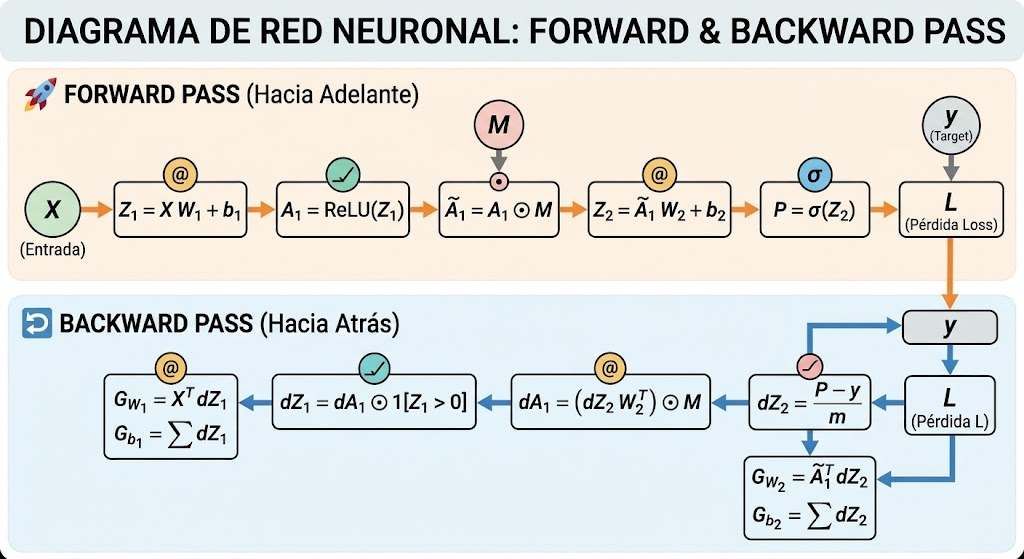

## 🔄 Núcleo del Backpropagation: Propagación Inversa del Error

Una vez calculado el error inicial en la capa de salida ($dZ_2$), debemos retropropagarlo a través de toda la red para obtener los gradientes de los pesos ($W$) y sesgos ($b$) de cada capa sin modificar los parámetros durante el trayecto.

### 1. Gradientes de la Capa de Salida ($W_2$ y $b_2$)

Utilizamos el error de salida $dZ_2$ y las activaciones de la capa oculta anterior ($\tilde{A}_1$):

$$G_{W_2} = \tilde{A}_1^T dZ_2$$

$$G_{b_2} = \sum_{rows} dZ_2$$

* **Detalle técnico:** La suma para el sesgo $G_{b_2}$ debe realizarse a lo largo de las filas del lote utilizando `keepdims=True` para preservar la dimensionalidad 2D de la matriz.

---

### 2. Propagación a través de la Capa Oculta y la Función ReLU ($dA_1$ y $dZ_1$)

Para mover el error hacia atrás desde la salida hasta la primera capa oculta, debemos cruzar los pesos $W_2$ y la función de activación ReLU:

$$dA_1 = (dZ_2 W_2^T) \odot M$$

$$dZ_1 = dA_1 \odot \mathbf{1}[Z_1 > 0]$$

* **$dA_1$**: Propaga el error hacia atrás multiplicándolo por la matriz de pesos transpuesta $W_2^T$. El símbolo $\odot$ denota multiplicación elemento a elemento (en NumPy, el operador `*`).
* **El rol de $M$ y $\tilde{A}_1$**: Actualmente, $M = 1$ y $\tilde{A}_1 = A_1$. Sin embargo, la estructura ya está diseñada para soportar *scaled dropout* en ejercicios avanzados, donde $M$ actuará como la máscara de dropout y $\tilde{A}_1 = A_1 \odot M$.
* **$dZ_1$ (Derivada de ReLU)**: La función indicadora $\mathbf{1}[Z_1 > 0]$ actúa como un filtro estricto. Si las neuronas estaban desactivadas ($Z_1 \le 0$) en el *forward pass*, su gradiente se bloquea a cero; si estaban activas ($Z_1 > 0$), el error pasa sin alteraciones.

---

### 3. Gradientes de la Primera Capa ($W_1$ y $b_1$)

Finalmente, utilizamos los datos de entrada originales de la red ($X$) y el error filtrado $dZ_1$ para calcular los gradientes de la primera capa:

$$G_{W_1} = X^T dZ_1$$

$$G_{b_1} = \sum_{rows} dZ_1$$

---

### ⚠️ Notas Clave de Implementación:
* **División por $m$**: La normalización del tamaño del lote ($m$) ocurre una sola vez y de forma nativa en el cálculo de $dZ_2$. **No** se debe volver a dividir entre $m$ dentro de estas ecuaciones.
* **Formato 2D**: Al programar las sumatorias de los sesgos ($G_{b_2}$ y $G_{b_1}$), asegúrate de configurar el parámetro `keepdims=True` para evitar errores de dimensiones (*broadcasting*) en NumPy.

In [23]:
def backward_student(P, yb, cache, params):
    """
    Realiza el paso hacia atrás (Backpropagation) para calcular los gradientes
    de todos los pesos y sesgos de la red neuronal.

    Parámetros de entrada:
    - P: Las probabilidades predichas por la red (salida de la función sigmoide).
    - yb: Las etiquetas reales (targets) correspondientes al lote actual.
    - cache: Diccionario que almacena los valores intermedios del paso hacia adelante
             (como 'X', 'Z1', 'A1_used' y las máscaras de dropout).
    - params: Diccionario que contiene los pesos y sesgos actuales de la red ('W1', 'b1', 'W2', 'b2').
    """

    # 1. Obtiene el tamaño del lote (m)
    m = len(yb)

    # 2. Computa el error o gradiente de la capa de salida (dZ2)
    dZ2 = (P - yb) / m

    # 3. Gradientes de la segunda capa (W2 y b2)
    dW2 = cache['A1_used'].T @ dZ2
    db2 = dZ2.sum(axis=0, keepdims=True)

    # Propaga el error hacia la capa oculta
    dA1 = (dZ2 @ params['W2'].T) * cache.get('mask', 1)

    # Aplica la derivada de la función ReLU
    dZ1 = dA1 * (cache['Z1'] > 0)

    # Calcula el gradiente para los pesos de la primera capa (W1)
    dW1 = cache['X'].T @ dZ1

    # Calcula el gradiente para los sesgos de la primera capa (b1)
    db1 = dZ1.sum(axis=0, keepdims=True)

    # Retorna un diccionario con todos los gradientes calculados
    return {'W1': dW1, 'b1': db1, 'W2': dW2, 'b2': db2}


## 📦 ¿Qué se almacena en la Caché (`cache`) durante el Forward Pass?

Para poder realizar el viaje de vuelta (Backpropagation) a la inversa, la red neuronal necesita rescatar valores clave que calculó previamente durante el recorrido hacia adelante:

* **`cache['X']`**: Almacena los datos de entrada originales de la red. Estos se utilizan al final de todo para calcular los gradientes de los pesos de la primera capa (`dW1`).
* **`cache['Z1']`**: Guarda los valores lineales de la capa oculta antes de pasar por la función ReLU. Funciona como un interruptor estricto (`Z1 > 0`) para anular el gradiente de las neuronas que estuvieron inactivas.
* **`cache['A1_used']`**: Contiene las activaciones de la capa oculta tras aplicar ReLU (y opcionalmente dropout). Sirve como la entrada aparente para calcular los pesos de la segunda capa (`dW2`).
* **`cache.get('mask', 1)`**: Almacena la máscara de escala de dropout aplicada en la capa oculta.

---

## 🔄 El Viaje a la Inversa: Reacción en Cadena del Backpropagation

El proceso de retropropagación funciona como una reacción en cadena escalonada de derecha a izquierda (desde la salida hacia la entrada), donde cada eslabón depende del anterior y de la caché:

* **1. Eslabón Inicial (Error de Salida):** Se calcula el gradiente inicial en la capa de salida comparando la predicción con la etiqueta real dividida entre el tamaño del lote: $dZ_2 = (P - y_b) / m$.
* **2. Gradientes de la Capa 2:** Se emplean las activaciones guardadas en `cache['A1_used']` junto con el error $dZ_2$ para obtener los gradientes de los pesos ($dW_2$) y sesgos ($db_2$) de la última capa.
* **3. Propagación hacia la Capa Oculta:** El error retrocede multiplicándose por la matriz de pesos transpuesta $W_2^T$ y aplicando la máscara almacenada. De esta forma se obtiene el error intermedio $dA_1$.
* **4. El Filtro de la Función ReLU:** Se cruza el "muro" de la activación evaluando las preactivaciones de `cache['Z1']` para anular el gradiente donde la neurona estuvo apagada ($Z_1 \le 0$). Esto da como resultado el error filtrado $dZ_1$.
* **5. Eslabón Final (Gradientes de la Capa 1):** Utilizando los datos de entrada originales guardados en `cache['X']` y el error filtrado $dZ_1$, se calculan finalmente los gradientes de los pesos ($dW_1$) y sesgos ($db_1$) de la primera capa.

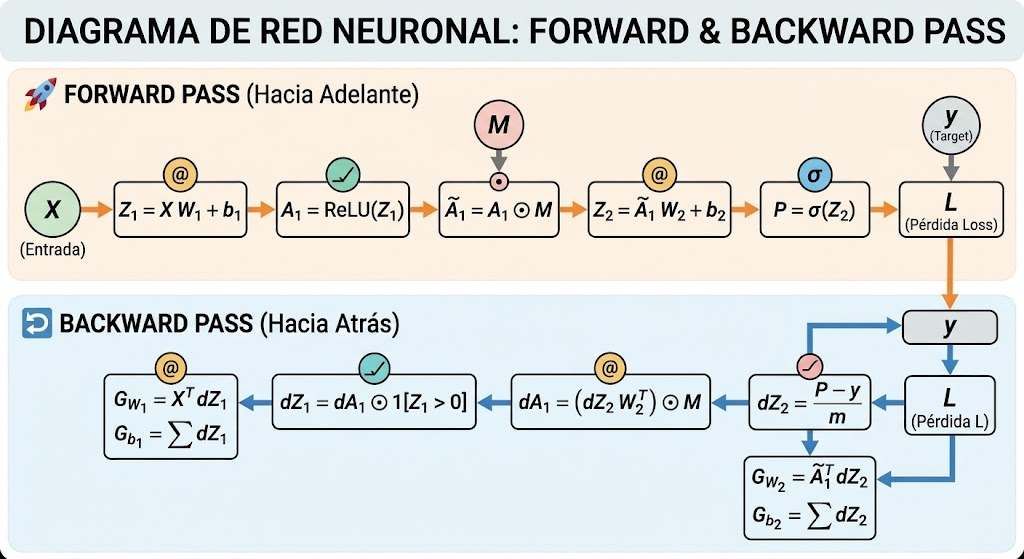

In [24]:
# Reference solution 3. Read only after trying the student cell.

# ==========================================
# 1. FUNCIÓN DE REFERENCIA: BACKPROPAGATION
# ==========================================
def backward_solution(P, yb, cache, params):
    """
    Calcula de forma exacta todos los gradientes de la red neuronal
    hacia atrás (desde la salida hasta la entrada).
    """

    # Calcula el error o gradiente inicial de la capa de salida (dZ2)
    # restando las etiquetas reales (yb) a las predicciones (P) y dividiendo entre el tamaño del lote.
    dZ2 = (P - yb) / len(yb)

    # Calcula los gradientes de los pesos de la segunda capa (dW2)
    # multiplicando las activaciones de la capa oculta transpuesta (A1T) por el error dZ2.
    # .T calcula la MATRIZ TRANSPUESTA
    dW2 = cache['A1_used'].T @ dZ2

    # Calcula los gradientes de los sesgos de la segunda capa (db2)
    # sumando los errores por filas y manteniendo la dimensión 2D con keepdims=True.
    db2 = dZ2.sum(axis=0, keepdims=True)

    # Propaga el error hacia la capa oculta (dA1) multiplicando el error dZ2
    # por la matriz de pesos W2 transpuesta y aplicando la máscara de dropout almacenada.
    # M es la "mascara"
    dA1 = (dZ2 @ params['W2'].T) * cache['mask']

    # Aplica la derivada de la función ReLU (dZ1) filtrando el error dA1
    # con las preactivaciones guardadas en Z1 (anula el gradiente si Z1 <= 0)
    dZ1 = dA1 * (cache['Z1'] > 0)

    # Calcula los gradientes de los pesos de la primera capa (dW1)
    # utilizando los datos de entrada originales X transpuestos multiplicados por el error filtrado dZ1.
    dW1 = cache['X'].T @ dZ1

    # Calcula los gradientes de los sesgos de la primera capa (db1)
    # sumando las filas del error dZ1.
    db1 = dZ1.sum(axis=0, keepdims=True)

    # Retorna un diccionario empaquetando todos los gradientes calculados.
    return {'W1': dW1, 'b1': db1, 'W2': dW2, 'b2': db2}

# ==========================================
# 2. BLOQUE DE PRUEBAS Y VALIDACIÓN (SANITY CHECKS)
# ==========================================

# Selecciona qué función evaluar (en este caso, la solución de referencia del profesor)
# choose ayuda a elegir entre 2 implementaciones
backward = choose(3, backward_student, backward_solution)

# Ejecuta el backpropagation utilizando un mini-lote de prueba (las primeras 5 muestras de y_train)
grads0 = backward(P0, y_train[:5], cache0, initial_params)

for key in initial_params:
    # 1. Prueba de dimensiones: Asegura que la forma (shape) del gradiente
    # coincida exactamente con la forma del parámetro original de la red.
    assert grads0[key].shape == initial_params[key].shape

    # 2. Prueba de estabilidad numérica: Comprueba que todos los valores calculados
    # sean finitos, garantizando que no existan errores de desbordamiento (NaN o Inf).
    assert np.isfinite(grads0[key]).all()

# Si todas las pruebas anteriores pasan con éxito, imprime en pantalla las dimensiones finales de los gradientes
print('Gradient shapes:', {k: v.shape for k, v in grads0.items()})

Gradient shapes: {'W1': (7, 20), 'b1': (1, 20), 'W2': (20, 1), 'b2': (1, 1)}


# DESCENSO DEL GRADIENTE

## 📉 Ejercicio 4: Actualización de los Parámetros (Descenso de Gradiente)

Una vez que hemos completado el *backpropagation* y calculado todos los gradientes, pasamos a la fase final de cada ciclo de entrenamiento: **actualizar los pesos y sesgos** de la red neuronal.

---

### 🔄 Diferencia Clave: Backpropagation vs. Descenso de Gradiente

* **Backpropagation (El detective del error):** Su único objetivo es analizar el error de salida y retropropagarlo para medir **cuánto debe cambiar cada parámetro**. El resultado de este paso son los **gradientes** ($\nabla L$, es decir, $dW_1, db_1, dW_2, db_2$). En esta fase **no se modifica ningún peso**, solo se calcula la dirección y magnitud del cambio necesario.
* **Descenso de Gradiente (El optimizador):** Toma esos gradientes recién calculados y aplica la regla matemática de corrección para **modificar físicamente los valores** de la red ($\theta$), haciendo que los pesos evolucionen hacia un estado donde la pérdida sea menor.

---

### 📐 La Ecuación de Actualización

Para actualizar cada parámetro de la red aplicamos la regla fundamental del descenso de gradiente:

$$\theta \leftarrow \theta - \eta \nabla L$$

### 🔍 Desglose de la fórmula y las reglas de programación:

* **$\theta$ (Theta):** Representa cada uno de los parámetros actuales de la red neuronal ($W_1, b_1, W_2, b_2$).
* **$\eta$ (Learning Rate o Tasa de Aprendizaje):** Es el hiperparámetro que controla qué tan grande o prudente es el paso que da la red al actualizar sus valores.
* **$\nabla L$ (Gradientes):** Son los derivados de la pérdida obtenidos durante el paso de retropropagación ($dW_1, db_1, dW_2, db_2$).
* **El signo menos ($-$):** Se usa obligatoriamente porque queremos **minimizar la pérdida** (*loss*). Dado que el gradiente apunta hacia la dirección donde el error aumenta, debemos movernos en el sentido opuesto para reducirlo.
* **Regla de oro en el código:** Al programar esta función, debes retornar un **nuevo diccionario** con los parámetros actualizados, asegurándote de **no modificar ni sobrescribir** los diccionarios originales para preservar la trazabilidad de los datos.

### Exercise 4: Update all the network parameters (weights)

Only after having completed the backward pass, apply the equation for the update of the weights, $\theta \leftarrow \theta - \eta\nabla L$, to every weight and bias. Here gradients mean derivatives of the loss, so the update uses a minus sign. Return a new dictionary; leave the old parameters unchanged.


In [25]:
"""
    Actualiza todos los parámetros de la red (pesos y sesgos)
    aplicando la regla del descenso de gradiente.

    Parámetros:
    - params: Diccionario con los parámetros actuales ('W1', 'b1', 'W2', 'b2').
    - grads: Diccionario con los gradientes calculados ('W1', 'b1', 'W2', 'b2').
    - learning_rate: La tasa de aprendizaje (η) que controla el tamaño del paso.

    Retorna:
    - Un NUEVO diccionario con los parámetros actualizados, dejando intactos los antiguos.
    """

def step_student(params, grads, learning_rate):


    #Recorremos cada llave (ej. 'W1', 'b1', etc.) en los parámetros.
    # Aplicamos la fórmula: Nuevo_Parametro = Parametro_Actual - (Learning_Rate * Gradiente)


    return {key: params[key] - learning_rate * grads[key] for key in params}  # Replace None with the descent update

### 💡 ¿Cómo funciona este código?
1. **`for key in params`**: Recorre cada uno de los parámetros de la red (tanto los pesos como los sesgos).
2. **`params[key]`**: Es el valor actual de $\theta$.
3. **`learning_rate * grads[key]`**: Representa el término $\eta \nabla L$ (el tamaño del paso multiplicado por su respectiva dirección de error).
4. **El signo menos (`-`)**: Mueve los pesos en sentido contrario al gradiente para **minimizar la pérdida**.
5. **Diccionario nuevo**: Al usar una comprensión de diccionarios (`{key: ... for key in params}`), creamos y retornamos un objeto totalmente nuevo sin alterar los diccionarios originales.

In [26]:
# Reference solution 4. Read only after trying the student cell.

# ==========================================
# 1. FUNCIÓN DE REFERENCIA: DESENSO DE GRADIENTE
# ==========================================

#Tiene 3 parametros
# Los parametors originales
# Las gradienes Calculadas en Backpropagation
# El Learning Rate

def step_solution(params, grads, learning_rate):
    """
    Actualiza los parámetros de la red aplicando la regla del descenso de gradiente.
    """
    # Retorna un nuevo diccionario aplicando la fórmula de actualización a cada parámetro:
    return {key: params[key] - learning_rate * grads[key] for key in params}

# ==========================================
# 2. BLOQUE DE PRUEBAS Y VALIDACIÓN (SANITY CHECKS)
# ==========================================

# Selecciona qué función evaluar (tu implementación de estudiante o la solución del profesor)
step = choose(4, step_student, step_solution)

# Realiza una copia de seguridad de los parámetros iniciales para comprobar la inmutabilidad
saved = copy_params(initial_params)

# Ejecuta la actualización de los parámetros utilizando los gradientes (grads0) y un learning rate de 1e-3
# EL LEARNING RATE LO definimos nosotros
updated = step(initial_params, grads0, 1e-3)

for key in initial_params:
    # 1. Comprueba que los parámetros originales no hayan sido alterados de forma imprevista
    np.testing.assert_array_equal(initial_params[key], saved[key])

    # 2. Verifica que el parámetro actualizado cumpla con precisión la fórmula del descenso de gradiente
    np.testing.assert_allclose(updated[key], saved[key] - 1e-3 * grads0[key])

# Realiza un nuevo recorrido hacia adelante (forward pass) utilizando los parámetros actualizados en un mini-lote
_, c_updated = forward_core(X_train[:5], updated)

# Prueba de oro de optimización: Valida de forma estricta que la nueva pérdida sea menor que la anterior
assert bce_from_logits(c_updated['Z2'], y_train[:5]) < bce_from_logits(cache0['Z2'], y_train[:5])

# Si todas las validaciones anteriores pasan con éxito, imprime el mensaje de confirmación de éxito
print('A sufficiently small gradient step lowered the loss on the same batch.')

A sufficiently small gradient step lowered the loss on the same batch.


## ⚙️ Parámetros de la Función de Actualización (`step_student`)

- def step_solution(params, grads, learning_rate):

La función encargada de aplicar el descenso de gradiente recibe exactamente **3 parámetros** fundamentales para poder corregir los valores de la red:

1. **`params` (Los parámetros originales):**
   * Corresponde al diccionario que contiene los pesos ($W_1, W_2$) y los sesgos ($b_1, b_2$) actuales de la red neuronal antes de ser modificados. Representan la posición actual ($\theta$) en el terreno del error.
2. **`grads` (Los gradientes calculados en Backpropagation):**
   * Es el diccionario con las derivadas de la pérdida ($dW_1, db_1, dW_2, db_2$) obtenidas tras ejecutar la retropropagación. Indican la dirección y la pendiente hacia donde el error aumenta o disminuye ($\nabla L$).
3. **`learning_rate` (La tasa de aprendizaje, $\eta$):**
   * El hiperparámetro numérico que controla la magnitud o el "tamaño del paso" que dará la red al aplicar los gradientes para actualizar sus valores.

## 🧠 Todo sobre el Learning Rate (Tasa de Aprendizaje, $\eta$)

El *Learning Rate* es uno de los hiperparámetros más críticos y delicados al entrenar cualquier red neuronal. Determina cómo evoluciona el aprendizaje mediante la ecuación de actualización $\theta \leftarrow \theta - \eta \nabla L$.

### 1. ¿Se define o se calcula?
* El Learning Rate **se define manualmente** antes de iniciar el entrenamiento. Es un hiperparámetro externo (por ejemplo, el valor `1e-3` o $0.001$).
* **No se calcula automáticamente** mediante las derivadas del *backpropagation*; la red no aprende cuál es el mejor valor por sí sola, por lo que requiere experimentación y pruebas por parte del programador.

### 2. ¿Cómo funciona?
Funciona como el **tamaño del paso** que da el optimizador en el terreno de la pérdida (*loss landscape*). El gradiente ($\nabla L$) indica la *dirección* en la que hay que moverse para reducir el error, pero el Learning Rate ($\eta$) escala la magnitud de ese movimiento:
* Si el gradiente es grande, un Learning Rate pequeño asegura un avance prudente.
* Si el Learning Rate es cero, la red se detiene por completo y no aprende nada.

---

### 3. Los Tres Escenarios del Learning Rate (El cuento de Ricitos de Oro)

Elegir un valor incorrecto puede arruinar por completo el entrenamiento de la red:

* **🔴 Un Learning Rate demasiado ALTO:**
  * **Qué pasa:** Los pasos son gigantescos. La red da saltos descontrolados, rebotando por encima del valle del error mínimo o alejándose cada vez más.
  * **Consecuencia:** La pérdida (*loss*) explota, oscila violentamente o el código termina arrojando errores de tipo `NaN` (valores numéricos no válidos por desbordamiento).

* **🔵 Un Learning Rate demasiado BAJO:**
  * **Qué pasa:** Los pasos son microscópicos (como avanzar a milímetros por año).
  * **Consecuencia:** Aunque la red sí aprende y la pérdida baja, el entrenamiento se vuelve **extremadamente lento**, pudiendo quedarse atrapada en mesetas o mínimos locales de los que nunca sale.

* **🟢 Un Learning Rate "Adecuado" (El punto exacto):**
  * **Qué pasa:** Es el equilibrio perfecto. Permite dar pasos grandes para avanzar rápido al principio, pero lo suficientemente prudentes para estabilizarse y asentarse de forma suave en el punto mínimo de error al acercarse al objetivo (como el valor `1e-3` probado en las validaciones).

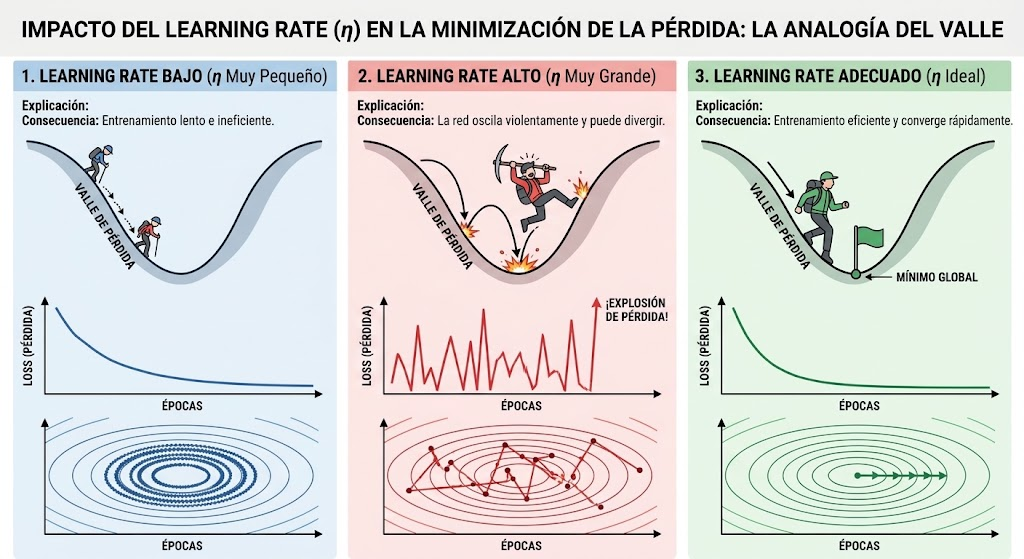

# Gradient Checking (Comprobación Numérica de Gradientes)

## 🔍 Verificación Numérica de Gradientes (Gradient Checking)

Hasta ahora hemos programado el *backpropagation* utilizando fórmulas analíticas derivadas a mano. Sin embargo, es muy fácil cometer errores sutiles (como una matriz transpuesta incorrecta, un signo cambiado o un factor de escala erróneo en el tamaño del lote). Para estar 100% seguros de que nuestro código funciona a la perfección, realizamos una **comprobación numérica**.

---

### 📐 ¿Cómo funciona la aproximación numérica?

Para cada parámetro $\theta_j$, el método compara el gradiente obtenido por *backpropagation* con una estimación empírica calculada mediante la **diferencia central**:

$$\frac{L(\theta_j + \epsilon) - L(\theta_j - \epsilon)}{2\epsilon}$$

* **¿Qué significa esto paso a paso?**
  1. Tomamos un peso o sesgo específico ($\theta_j$).
  2. Le sumamos un valor infinitesimal ($\epsilon$) y evaluamos la pérdida resultante ($L$).
  3. Le restamos ese mismo valor infinitesimal ($\epsilon$) y evaluamos la pérdida de nuevo.
  4. La diferencia entre ambas pérdidas dividida por $2\epsilon$ nos entrega una pendiente empírica sumamente precisa.

---

### 🎯 ¿Por qué es crucial esta validación?

* **Atrapa errores ocultos:** Detecta fallos invisibles a simple vista como inversiones de signos, problemas en las sumas de los sesgos, factores de lote incorrectos o transposiciones fallidas en NumPy.
* **Redes de prueba (*Toy Inputs*):** Se ejecuta utilizando una red pequeña y datos simples (evitando zonas complejas como los puntos críticos de la función ReLU en cero) para garantizar que la prueba sea rápida, limpia y 100% confiable.

> **Regla de oro:** Al igual que en la programación tradicional, al construir redes neuronales desde cero siempre es fundamental verificar que cada bloque funcione correctamente con entradas simples antes de pasar al entrenamiento masivo.

### Check the calculus numerically

For a parameter $\theta_j$, compare backpropagation with the central difference
$[L(\theta_j+\epsilon)-L(\theta_j-\epsilon)]/(2\epsilon)$.
We check every parameter of a small network, using a toy input away from ReLU's kink at zero. This catches incorrect transposes, signs, bias sums, and factors of batch size.

When coding, it is always important to check everything works properly with very simple inputs

In [28]:
# ==========================================
# FUNCIÓN DE VERIFICACIÓN NUMÉRICA DE GRADIENTES
# ==========================================
def gradient_check(forward_fn, dropout_rate=0.0):
    """
    Compara los gradientes analíticos (calculados por backpropagation)
    con los gradientes numéricos (calculados por diferencias finitas)
    para validar que el código de retropropagación sea matemáticamente correcto.
    """

    # 1. Inicializamos una red pequeña de prueba ("toy network") con una semilla fija
    params = initialize(3, n_hidden=4, seed=81)

    # 2. Creamos entradas artificiales (xb) y etiquetas binarias falsas (yb) para el mini-lote
    xb = np.random.default_rng(82).normal(size=(5, 3))
    yb = np.array([[0.], [1.], [0.], [1.], [1.]])

    def evaluate(p):
        """
        Función auxiliar para realizar el forward pass.
        Fija la semilla del generador aleatorio (RNG) para garantizar que,
        si se usa Dropout, la máscara de apagado sea exactamente la misma en cada llamada.
        """
        # Recreate this RNG on every call: finite differences need the SAME mask.
        return forward_fn(xb, p, training=True, dropout_rate=dropout_rate,
                          rng=np.random.default_rng(83))

    # Ejecutamos el forward pass inicial con los parámetros base
    prob, cache = evaluate(params)

    # Aseguramos que los valores de Z1 estén alejados de cero para evitar puntos de inflexión de la ReLU
    assert np.min(np.abs(cache['Z1'])) > 1e-4

    # Obtenemos los gradientes oficiales usando nuestro código analítico (Backpropagation)
    analytic = backward(prob, yb, cache, params)

    # Inicializamos un diccionario de ceros para guardar los gradientes numéricos
    numeric = {k: np.zeros_like(v) for k, v in params.items()}

    #---------------VALOR INFINITISEMAL---------------
    # Definimos un valor infinitesimal (epsilon) para la aproximación de la derivada
    eps = 1e-6

    # 3. BUCLE DE DIFERENCIAS FINITAS (Cálculo Numérico)
    for key, value in params.items():
        # Recorremos cada elemento (índice) individual dentro de cada matriz de parámetros (W1, b1, etc.)
        for index in np.ndindex(value.shape):
            # Creamos dos copias idénticas de los parámetros
            plus, minus = copy_params(params), copy_params(params)

            # Sumamos y restamos epsilon en la posición específica [key][index]
            plus[key][index] += eps
            minus[key][index] -= eps

            # Evaluamos la pérdida con el parámetro ligeramente incrementado y decrementado
            _, cp = evaluate(plus)   # p es PLUS
            _, cm = evaluate(minus)  # m es MINUS

            # LA LOSS FUNCTION ES LA BINARY CROSS ENTROPY (BCE)
            # L es "bce_from_logits"
            # Aplicamos la fórmula de la diferencia central: [L(theta + eps) - L(theta - eps)] / (2 * eps)
            numeric[key][index] = (bce_from_logits(cp['Z2'], yb)
                                   - bce_from_logits(cm['Z2'], yb)) / (2*eps)

    # 4. VALIDACIÓN ESTRICTA
    # Comparamos matemáticamente el gradiente analítico frente al numérico usando tolerancias estrictas
        np.testing.assert_allclose(analytic[key], numeric[key], rtol=2e-5, atol=2e-7)

    # Calculamos el error absoluto máximo encontrado entre ambos métodos
    err = max(np.max(np.abs(analytic[k] - numeric[k])) for k in params)

    print(f'Gradient check passed (dropout={dropout_rate:g}); max absolute error = {err:.2e}')

# ==========================================
# EJECUCIÓN DE LA PRUEBA SIN DROPOUT
# ==========================================
def no_dropout_forward(Xb, params, **kwargs):
    """
    Función envolvente para ejecutar el forward pass estándar sin dropout.
    """
    return forward_core(Xb, params)

#------------------MAIN--------------------------
# Ejecutamos la verificación de gradientes llamando a nuestra función envolvente
gradient_check(no_dropout_forward)

Gradient check passed (dropout=0); max absolute error = 1.00e-10


# EPOCAS, Y ESQUEMAS DE DESCENSO DE GRADIENTE

## 🔄 Conceptos Clave de esta Sección: Épocas y Esquemas

### 1. ¿Qué es una Época (*Epoch*)?
* Es **un recorrido completo** a través de todas las filas de datos de entrenamiento disponibles.
* En el aprendizaje estocástico y por mini-lotes, los datos se barajan aleatoriamente (*random reshuffling*) al inicio de cada época para evitar que la red neuronal memorice el orden artificial de las muestras.

---

### 2. Los Tres Esquemas de Actualización de Gradientes

* **`stochastic` (Gradiente Descendente Estocástico / SGD Stochastic Gradient Descent puro):**
  * **Filas por actualización:** 1 sola muestra por cada paso.
  * **Actualizaciones por época:** $N$ (tantas como filas tenga el conjunto de datos). Es un esquema muy ruidoso, pero avanza rápido por cada muestra individual.

* **`batch` (Gradiente Descendente por Lote Completo):**
  * **Filas por actualización:** Todas las filas de entrenamiento ($N$) al mismo tiempo.
  * **Actualizaciones por época:** 1 sola actualización. Calcula el gradiente promedio exacto de todo el dataset antes de mover un solo peso, pero resulta muy costoso en memoria si los datos son gigantescos.

* **`minibatch` (Gradiente Descendente por Mini-lotes):**
  * **Filas por actualización:** Un subconjunto de tamaño fijo (`batch_size`, por ejemplo, 32 o 64).
  * **Actualizaciones por época:** El resultado de dividir el total de filas entre el tamaño del lote redondeado hacia arriba ($\lceil N / \text{batch\_size} \rceil$). Es el estándar de la industria porque combina lo mejor de ambos mundos (eficiencia computacional y estabilidad en la convergencia).

## One optimizer, three different batch sizes and gradient update schemes

Since we are at it, we will try to implement dropout (the regularizer) while we implement the gradient update schemes)

| `Scheme` | Rows used for each update | Updates per epoch |
|---|---|---|
| `stochastic` | 1 | $N$ |
| `batch` | all $N$ training rows | 1 |
| `minibatch` | up to `batch_size` | $\lceil N/\text{batch\_size}\rceil$ |

An **epoch** is one pass through all training rows. For stochastic and minibatch descent we use a new random permutation each epoch (random reshuffling, without replacement within that epoch). Keep the final, possibly smaller batch and divide its loss gradient by its **actual** size. A full batch averages all training examples before updating any parameter.

### Exercise 5: stochastic/batch/minibatch iterators

**Predict:** For N=10 and minibatch size 4, what are the batch sizes? How many updates?

**Code:** Set `size` for the three schemes, then yield slices of the permutation. The checks verify full coverage, no repeats, and the short final batch.

## 🔮 Ejercicio 5 (Parte de Predicción): Lotes y Actualizaciones

### 📌 Pregunta de Análisis:
> *Para $N = 10$ filas de entrenamiento y un tamaño de minibatch de $4$, ¿cuáles son los tamaños de los lotes y cuántas actualizaciones ocurren?*

---

### 📦 1. ¿Cuáles son los tamaños de los lotes (*batch sizes*)?
* Al dividir las $10$ muestras de entrenamiento en bloques de tamaño $4$, los lotes sucesivos que procesa la red tendrán longitudes de: **$4$, $4$ y $2$**.
* El último lote absorbe automáticamente el sobrante final de elementos restantes.

---

### ⚡ 2. ¿Cuántas actualizaciones (*updates*) ocurren por época?
* Ocurren **$3$ actualizaciones** en total por cada época de entrenamiento (una por cada lote procesado: $4 + 4 + 2 = 10$).
* Matemáticamente, esto equivale a redondear hacia arriba la división del total de muestras entre el tamaño del lote: $\lceil 10 / 4 \rceil = 3$.

In [30]:
# Note: `size` is to be filled from your knowledge and from the input arguments of the function.
# You have all the information needed


# ==========================================
# EJERCICIO 5: ITERADORES DE ENTRENAMIENTO
# (Stochastic / Batch / Minibatch)
# ==========================================

def batch_indices_student(n, scheme, batch_size, rng):
    """
    Genera los índices para recorrer los datos de entrenamiento según
    el esquema de actualización seleccionado (stochastic, batch o minibatch).
    """

    # 1. Definimos el tamaño del bloque (size) dependiendo del esquema elegido:
    if scheme == 'stochastic':
        size = 1  # this is a fixed number
        # Procesa 1 sola muestra por cada actualización.

    elif scheme == 'batch':
        size = n  # this is a fixed number
        # Procesa todas las filas (n) en una sola actualización.

    elif scheme == 'minibatch':
        size = batch_size  # this is a number that you can choose, with some boundaries. Which boundaries?
        # Utiliza el tamaño de lote personalizado y configurable.
    else:
        raise ValueError('Unknown scheme')

    # 2. Creamos el orden de los índices:
    # Si es 'batch', se mantiene el orden secuencial (0 a n-1).
    # Si es 'stochastic' o 'minibatch', se barajan aleatoriamente usando el generador (rng) al inicio de cada época.
    order = np.arange(n) if scheme == 'batch' else rng.permutation(n)

    # 3. Recorremos los datos en bloques de tamaño 'size' y devolvemos la porción correspondiente (slice)
    for start in range(0, n, size):
        yield order[start:start + size]  # Slice order, including any short final batch
        # Incluye automáticamente cualquier lote final más pequeño

In [33]:
# Reference solution 5. Read only after trying the student cell.

# ==========================================
# SOLUCIÓN DE REFERENCIA Y PRUEBAS AUTOMÁTICAS (EJERCICIO 5)
# ==========================================

def batch_indices_solution(n, scheme, batch_size, rng):
    """
    Versión de referencia oficial que incluye validaciones de seguridad robustas
    antes de aplicar la lógica de iteración de índices.
    """
    # [NUEVO] Validación de seguridad: Asegura que n sea un número entero estrictamente positivo.
    if not isinstance(n, (int, np.integer)) or n < 1:
        raise ValueError('n must be a positive integer')
    if scheme == 'stochastic':
        size = 1
    elif scheme == 'batch':
        size = n
    elif scheme == 'minibatch':
        # [NUEVO] Validación de seguridad: Asegura que batch_size también sea un entero positivo.
        if not isinstance(batch_size, (int, np.integer)) or batch_size < 1:
            raise ValueError('batch_size must be a positive integer')
        size = int(batch_size)
        # [NUEVO] Lanza un error explícito si se escribe un esquema inválido.
    else:
        raise ValueError('scheme must be stochastic, batch or minibatch')

    # Orden secuencial para 'batch' o permutación aleatoria para 'stochastic' / 'minibatch'
    order = np.arange(n) if scheme == 'batch' else rng.permutation(n)

    # Recorrido y generación de bloques (slices)
    for start in range(0, n, size):
        yield order[start:start+size]

# ==========================================
# BANCO DE PRUEBAS AUTOMÁTICAS (TESTS)
# ==========================================

# Función utilitaria que selecciona dinámicamente entre tu código (student) o la referencia (solution)
batch_indices = choose(5, batch_indices_student, batch_indices_solution)

# Bucle que evalúa los tres esquemas probando sus tamaños esperados para N=10
for scheme, sizes in [('stochastic', [1]*10), ('batch', [10]), ('minibatch', [4, 4, 2])]:

    # Genera la lista de lotes utilizando un generador aleatorio con semilla fija
    batches = list(batch_indices(10, scheme, 4, np.random.default_rng(2)))

    # Aserción de tamaños: Comprueba que las longitudes de los lotes generados coincidan exactamente con lo esperado
    assert [len(b) for b in batches] == sizes

    # Aserción de cobertura: Une y ordena todos los índices para verificar que están los números del 0 al 9 sin duplicados ni faltantes
    np.testing.assert_array_equal(np.sort(np.concatenate(batches)), np.arange(10))
    print(scheme, 'batch sizes:', [len(b) for b in batches])

# ----------Prueba de caso límite (Edge Case)-------------
# Verifica que si configuras un batch_size (20) mayor que el total de muestras (10),
# el sistema no falle y devuelva un único lote que agrupe todo el dataset (longitud 1).
assert len(list(batch_indices(10, 'minibatch', 20, np.random.default_rng(2)))) == 1

stochastic batch sizes: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
batch batch sizes: [10]
minibatch batch sizes: [4, 4, 2]


<details>
<summary>Worked answer — open after discussing</summary>

The minibatch sizes are 4, 4 and 2; there are three updates. Stochastic descent makes ten updates, while batch descent makes one. A minibatch size at least N gives one full-data update. A minibatch size of one gives stochastic descent when order, initialization and learning rate match.

</details>


## 💡 Solución Explicada: Comparación de Esquemas de Actualización ($N = 10$)

* **Tamaño de los minilotes y número de actualizaciones:**
  Para un total de $N = 10$ muestras de entrenamiento divididas en bloques de tamaño $4$, los tamaños de los minilotes resultantes son **$4$, $4$ y $2$**, lo que da como resultado un total de **tres actualizaciones** por época.

* **Comparación entre esquemas (Estocástico vs. Lote Completo):**
  * El descenso **estocástico** procesa las muestras una por una, realizando un total de **diez actualizaciones** por época.
  * El descenso por **lote completo (*batch*)** procesa todo el conjunto de datos de golpe, realizando una **sola actualización** por época.

* **Casos límite y equivalencias importantes:**
  * **Lote completo equivalente:** Configurar un tamaño de minilote mayor o igual al total de muestras ($N$) equivale a realizar una única actualización con todos los datos.
  * **Descenso estocástico equivalente:** Configurar un tamaño de minilote de exactamente uno ($1$) reproduce el comportamiento del descenso estocástico, siempre y cuando el orden de los datos, la inicialización de los pesos y la tasa de aprendizaje coincidan.

# ------------------------DROPOUT---------------------------------------------

## Dropout: switch units off only while training, with the effect of a regularization technique

### Exercise 6: Inverted dropout

Let $r$ be the **drop probability** and $q=1-r$ the keep probability. For each row and hidden unit independently, draw $K_{ij}\sim\mathrm{Bernoulli}(q)$ and use

$$M=K/q,\qquad \widetilde A_1=A_1\odot M.$$

Then $\mathbb E[\widetilde A_1\mid A_1]=A_1$. The factor $1/q$ is applied **during training**, so evaluation uses the unmodified activations and needs no rescaling. Dropout is applied after hidden ReLU, never to the output probability. Draw a fresh mask for each training forward pass; cache and reuse that very mask in the backward pass.

**Code:** Draw a mask using `rng.random(A.shape)`, compare it with `q`, then scale it. This is equivalent to sampling from a Bernoulli distribution with `p = rate` and `q = -(rate)` Return both the dropped activation and the scaled mask. The no-dropout/evaluation branch is supplied.

**Discuss:** Why must backpropagation multiply by the same scaled mask? Why should validation use `training=False`?


In [ ]:
def dropout_student(A, rate, training, rng):
    if not 0 <= rate < 1:
        raise ValueError('dropout rate must be in [0, 1)')
    if not training or rate == 0:
        return A, np.ones_like(A)
    q = 1-rate
    mask = None  # Bernoulli keep mask divided by q
    return None, mask  # Multiply A elementwise by this mask

In [ ]:
# Reference solution 6. Read only after trying the student cell.

def dropout_solution(A, rate, training, rng):
    if not 0 <= rate < 1:
        raise ValueError('dropout rate must be in [0, 1)')
    if not training or rate == 0:
        return A, np.ones_like(A)
    if rng is None:
        raise ValueError('Provide an RNG for training with dropout')
    q = 1-rate
    mask = (rng.random(A.shape) < q).astype(float) / q
    return A * mask, mask



In [9]:
dropout = choose(6, dropout_student, dropout_solution)

def forward(Xb, params, training=False, dropout_rate=0.0, rng=None):
    # Reuse the forward core you wrote. Recompute the output after dropout.
    P, cache = forward_core(Xb, params)
    A1_used, mask = dropout(cache['A1'], dropout_rate, training, rng)
    Z2 = A1_used @ params['W2'] + params['b2']
    cache.update(A1_used=A1_used, mask=mask, Z2=Z2)
    return sigmoid(Z2), cache

ones = np.ones((10000, 20))
dropped, mask = dropout(ones, 0.25, True, np.random.default_rng(9))
assert abs(dropped.mean() - 1) < 0.01
assert abs(np.mean(mask == 0) - 0.25) < 0.01
np.testing.assert_allclose(np.unique(mask), [0, 1/0.75])
np.testing.assert_array_equal(dropout(ones, 0.25, False, None)[0], ones)
np.testing.assert_array_equal(dropout(ones, 0, True, None)[0], ones)
peval1, _ = forward(X_train[:5], initial_params, dropout_rate=0.25)
peval2, _ = forward(X_train[:5], initial_params, dropout_rate=0.25)
np.testing.assert_array_equal(peval1, peval2)
np.testing.assert_allclose(peval1, P0)
gradient_check(forward, dropout_rate=0.25)
print('Dropout checks passed; evaluation predictions are deterministic.')


NameError: name 'choose' is not defined

<details>
<summary>Worked answer — open after discussing</summary>

The local derivative of A×M with respect to A is M. Dropped units receive zero gradient through that activation; kept units receive the same 1/q factor used in the forward pass. Drawing a different mask in the backward pass would differentiate a different function. Deterministic validation measures the inference network rather than a randomly thinned network. Preserving expected hidden activations does not imply that the full nonlinear network exactly equals the average of all dropout networks.

</details>

## Put it all together: a full training loop

For each epoch: construct batches $\to$ forward pass with dropout active $\to$ compute gradients $\to$ update **all** parameters $\to$ measure train and validation metrics with dropout **disabled**.

All logged losses are evaluated on the complete corresponding split using one fixed parameter state, after the epoch. They are not averages of online losses from changing models. This makes train and validation curves comparable, including when training used dropout.

The loop records epoch, cumulative updates, examples seen and elapsed time. It returns the final parameters and the checkpoint with the smallest validation BCE (including the initial model at epoch 0). It never receives the test set. For paired comparisons, initialization, shuffle and dropout each have their own random stream; changing dropout cannot change the data order.


In [ ]:
def metrics(params, Xb, yb):
    P, cache = forward(Xb, params, training=False)
    return {'loss': bce_from_logits(cache['Z2'], yb),
            'accuracy': float(np.mean((P >= 0.5) == yb))}

def train(Xtr, ytr, Xva, yva, *, scheme='minibatch', batch_size=32,
          dropout_rate=0.0, learning_rate=0.05, epochs=120,
          seed=0, n_hidden=20):
    if scheme not in ('stochastic', 'batch', 'minibatch'):
        raise ValueError('Unknown scheme')
    if not 0 <= dropout_rate < 1 or learning_rate <= 0:
        raise ValueError('Invalid dropout rate or learning rate')
    if not isinstance(epochs, (int, np.integer)) or epochs < 1:
        raise ValueError('epochs must be a positive integer')
    assert Xtr.ndim == Xva.ndim == 2 and Xtr.shape[1] == Xva.shape[1]
    assert ytr.shape == (len(Xtr), 1) and yva.shape == (len(Xva), 1)
    params = initialize(Xtr.shape[1], n_hidden, seed=seed)
    shuffle_rng = np.random.default_rng(seed + 10000)
    dropout_rng = np.random.default_rng(seed + 20000)
    updates, seen = 0, 0
    rows = []
    start_time = time.perf_counter()
    best_loss, best_epoch, best_params = np.inf, 0, copy_params(params)
    for epoch in range(epochs + 1):
        if epoch > 0:
            for ids in batch_indices(len(Xtr), scheme, batch_size, shuffle_rng):
                P, cache = forward(Xtr[ids], params, training=True,
                                   dropout_rate=dropout_rate, rng=dropout_rng)
                grads = backward(P, ytr[ids], cache, params)
                params = step(params, grads, learning_rate)
                updates += 1
                seen += len(ids)
        tr, va = metrics(params, Xtr, ytr), metrics(params, Xva, yva)
        if not np.isfinite([tr['loss'], va['loss']]).all():
            raise FloatingPointError('Nonfinite loss: inspect gradients or lower learning_rate')
        rows.append({'epoch': epoch, 'updates': updates, 'examples_seen': seen,
                     'seconds': time.perf_counter()-start_time,
                     'train_loss': tr['loss'], 'val_loss': va['loss'],
                     'train_accuracy': tr['accuracy'], 'val_accuracy': va['accuracy']})
        if va['loss'] < best_loss:
            best_loss, best_epoch, best_params = va['loss'], epoch, copy_params(params)
    return {'final_params': params, 'best_params': best_params,
            'best_epoch': best_epoch, 'history': pd.DataFrame(rows)}

# Equivalence checks on real training rows, with the same order and RNG streams.
small = (X_train[:10], y_train[:10], X_val[:8], y_val[:8])
a = train(*small, scheme='stochastic', epochs=2, seed=11, dropout_rate=0.25)
b = train(*small, scheme='minibatch', batch_size=1, epochs=2, seed=11, dropout_rate=0.25)
for key in a['final_params']:
    np.testing.assert_allclose(a['final_params'][key], b['final_params'][key])
a = train(*small, scheme='batch', epochs=2, seed=11)
b = train(*small, scheme='minibatch', batch_size=10, epochs=2, seed=11)
for key in a['final_params']:
    np.testing.assert_allclose(a['final_params'][key], b['final_params'][key], atol=1e-12)
for scheme, count in [('stochastic', 10), ('batch', 1), ('minibatch', 3)]:
    run = train(*small, scheme=scheme, batch_size=4, epochs=2)
    assert run['history']['updates'].iloc[-1] == 2*count
    assert run['history']['examples_seen'].iloc[-1] == 20
print('Training-loop checks passed, including the short final minibatch.')


## Comparison between the 3 schemes with 2 different dropout settings each

**Before running, predict:** Which curve will improve fastest per epoch? Which run will take longest? Will dropout necessarily help on this small dataset?

For the main comparison hold fixed the split, preprocessing, architecture (20 hidden units), learning rate (0.05), and epoch count (120). Compare `stochastic`, `batch`, and `minibatch` (size 32), each with drop probability **0 or 0.25**. Run three paired seeds, with identical initial weights within each seed. The train/validation split stays fixed, so the spread reflects training randomness, **not uncertainty over possible datasets**.

Equal epochs mean equal examples processed, but unequal updates and elapsed time. A common learning rate is a controlled teaching baseline, not an individually optimized contest. Do not conclude that a method is intrinsically better from this one setting. Per-scheme learning-rate tuning is an extension below.

The learning curves use every epoch; final-epoch bars compare the same epoch budget. Best-validation checkpoints are used only for the final selected-model diagnostic. Runtime includes epoch-end metrics and Python overhead; it is not a hardware-independent benchmark.


In [10]:
SCHEMES = ['stochastic', 'batch', 'minibatch']
DROP_RATES = [0.0, 0.25]
SEEDS = [7, 19, 41]  # use one seed for a quicker first pass; restore all three for discussion
EPOCHS = 120
LEARNING_RATE = 0.05
BATCH_SIZE = 32
COLORS = dict(zip(SCHEMES, ['#167d9a', '#d47a25', '#7454ad']))

def label(scheme, rate):
    return f'{scheme}, dropout={rate:g}'

runs = {}
for seed in SEEDS:
    for scheme in SCHEMES:
        for rate in DROP_RATES:
            runs[(scheme, rate, seed)] = train(
                X_train, y_train, X_val, y_val, scheme=scheme,
                batch_size=BATCH_SIZE, dropout_rate=rate,
                learning_rate=LEARNING_RATE, epochs=EPOCHS, seed=seed)
    print(f'Completed seed {seed}')

records = []
for (scheme, rate, seed), run in runs.items():
    end = run['history'].iloc[-1]
    records.append({'scheme': scheme, 'dropout': rate, 'seed': seed,
                    'final_train_BCE': end.train_loss, 'final_val_BCE': end.val_loss,
                    'final_val_accuracy': end.val_accuracy,
                    'gap_BCE': end.val_loss-end.train_loss,
                    'best_val_BCE': run['history'].val_loss.min(),
                    'best_epoch': run['best_epoch'], 'updates': int(end.updates),
                    'seconds': end.seconds})
results = pd.DataFrame(records)
display(results.groupby(['scheme', 'dropout'], sort=False).agg(
    final_val_BCE=('final_val_BCE', 'mean'),
    final_val_accuracy=('final_val_accuracy', 'mean'),
    gap_BCE=('gap_BCE', 'mean'), updates=('updates', 'first'),
    mean_seconds=('seconds', 'mean')).round(4))


NameError: name 'train' is not defined

### First output: Learning curves at an equal epoch budget

Solid curves are training BCE; dashed curves are validation BCE. Shading shows ±1 sample standard deviation across seeds (no shading if only one seed). All metrics use dropout-free inference. Look for stalled optimization, decreasing training loss, and any train–validation divergence.


In [ ]:
def mean_sd(values):
    values = np.asarray(values)
    return values.mean(axis=0), (values.std(axis=0, ddof=1) if len(values)>1
                                  else np.zeros_like(values[0]))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharex=True, sharey=True)
for ax, scheme in zip(axes, SCHEMES):
    for rate, color in zip(DROP_RATES, ['#167d9a', '#d47a25']):
        for metric, style, split in [('train_loss', '-', 'train'), ('val_loss', '--', 'validation')]:
            hs = [runs[(scheme, rate, s)]['history'] for s in SEEDS]
            avg, sd = mean_sd([h[metric].to_numpy() for h in hs])
            epochs = hs[0]['epoch'].to_numpy()
            ax.plot(epochs, avg, style, color=color, label=f'{split}, drop={rate:g}')
            ax.fill_between(epochs, avg-sd, avg+sd, color=color, alpha=0.08)
    ax.set(title=scheme, xlabel='Epoch'); ax.legend(fontsize=8)
axes[0].set_ylabel('Mean binary cross-entropy')
fig.suptitle('Learning curves · mean ± 1 SD across training seeds')
plt.tight_layout(); plt.show()


### Second output: the horizontal axis changes the question

Compare mean validation BCE against **epochs**, **cumulative parameter updates**, and **elapsed seconds**. The last two axes use a symmetric logarithmic scale to include zero and show the different budgets. Each point is an epoch-end measurement; no within-epoch loss was measured. The time coordinate is the mean elapsed time across seeds at that epoch.

The update plot re-expresses the same runs; it is not a separately trained equal-update-budget experiment. One full-batch update touches N examples, whereas one stochastic update touches one. Neither epochs nor updates alone measure all computational costs.


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for scheme in SCHEMES:
    for rate in DROP_RATES:
        hs = [runs[(scheme, rate, s)]['history'] for s in SEEDS]
        avg, _ = mean_sd([h.val_loss.to_numpy() for h in hs])
        for ax, xkey in zip(axes, ['epoch', 'updates', 'seconds']):
            xavg = np.mean([h[xkey].to_numpy() for h in hs], axis=0)
            ax.plot(xavg, avg, color=COLORS[scheme], linestyle='-' if rate == 0 else '--',
                    label=label(scheme, rate))
axes[0].set(xlabel='Epoch', ylabel='Validation BCE', title='Equal passes through the data')
axes[1].set(xlabel='Parameter updates', title='Different update counts')
axes[1].set_xscale('symlog', linthresh=1)
axes[2].set(xlabel='Elapsed seconds (includes metrics)', title='Measured runtime')
axes[2].set_xscale('symlog', linthresh=0.01)
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

NameError: name 'plt' is not defined

### Third output: does dropout improve generalization here?

Compare final validation BCE (lower is better), validation accuracy at threshold 0.5 (higher is better), and the BCE gap **validation minus training**. Error bars show one sample SD across seeds. A smaller gap alone does not prove improvement: it can also arise when both losses are poor.


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
xpos = np.arange(len(SCHEMES))
for j, rate in enumerate(DROP_RATES):
    for ax, metric, title in zip(axes,
        ['final_val_BCE', 'final_val_accuracy', 'gap_BCE'],
        ['Validation BCE ↓', 'Validation accuracy ↑', 'BCE generalization gap']):
        values = [results[(results.scheme==s) & (results.dropout==rate)][metric].to_numpy()
                  for s in SCHEMES]
        means = [v.mean() for v in values]
        sds = [v.std(ddof=1) if len(v)>1 else 0 for v in values]
        ax.bar(xpos+(j-0.5)*0.36, means, width=0.36, yerr=sds, capsize=4,
               color=['#167d9a', '#d47a25'][j], label=f'dropout={rate:g}')
        ax.set_xticks(xpos, SCHEMES, rotation=15)
        ax.set_title(title); ax.legend(fontsize=8)
axes[1].set_ylim(0, 1)
axes[2].axhline(0, color='black', linewidth=0.7)
fig.suptitle(f'Final epoch {EPOCHS} · mean ± 1 SD across seeds')
plt.tight_layout(); plt.show()

paired = results.pivot(index=['scheme', 'seed'], columns='dropout', values='final_val_BCE')
paired['dropout_minus_no_dropout'] = paired[0.25] - paired[0.0]
print('Paired change in final validation BCE (negative favours dropout):')
display(paired[['dropout_minus_no_dropout']].round(4))


NameError: name 'plt' is not defined

### Discuss the result and try to give some answers

1. Which configuration has the smallest mean final validation BCE? Is its accuracy ranking identical?
2. Is the fastest improvement per epoch also fastest per update or per second? Explain the batch-size dependence.
3. Identify a curve consistent with undertraining or overfitting. What additional experiment would distinguish them?
4. Use the paired table: does dropout help consistently across seeds and schemes? Could it hurt this small model?
5. Why are the error bars not confidence intervals for performance on all houses?

**Your answers:**

1. …
2. …
3. …
4. …
5. …


<details>
<summary>Worked answer — open after discussing</summary>

The basic take-home message is: read the actual output rather than assuming what will be the winner. BCE uses the full probability scores and penalizes confidently wrong predictions; accuracy only considers which side of 0.5 a score lies on, so rankings can differ. At fixed epochs, stochastic descent has many more updates; its Python loop may still make it slower in wall time. A batch curve that is still decreasing at the final epoch suggests testing more epochs or a larger learning rate. Falling training BCE with rising validation BCE is consistent with overfitting, but a small validation sample adds noise. Dropout may reduce overfitting, have little effect, or cause underfitting; check validation BCE rather than the gap alone. The three seeds reuse one split and do not measure sampling uncertainty in a new population.

</details>


### Some comments on the saved reference run

With the default settings, the mean **final validation BCE** is approximately 0.249 for stochastic descent, 0.311 for minibatch descent and 0.609 for full-batch descent without dropout. Their update counts are 33,000, 1,080 and 120 respectively. The full-batch curve is still declining, so this result compares the stated training budgets rather than best attainable performance. You could keep training the full-batch curve for longer (until convergence).

For stochastic descent, adding dropout changes mean validation BCE from about 0.249 to 0.252 while mean accuracy increases from about 90.6% to 91.7%. This illustrates why accuracy and BCE can rank models differently. Dropout also raises mean BCE in the other two schemes in this run; regularization is not guaranteed to help. The small negative minibatch generalization gap is possible because the validation sample can be easier than the training sample.

These numbers describe the embedded default run. If you change the settings or implementations, use your newly generated outputs to update this interpretation.

## 8 · Freeze a choice, then inspect the held-out test set

**Selection rule fixed here:** choose the scheme/dropout pair with the lowest mean *best-checkpoint validation BCE* over the training seeds. For its diagnostic model, use the first predeclared seed (never choose a seed based on test performance) and that run's best-validation checkpoint. Report which epoch was selected.

The test set is used only below. The three comparison plots above are validation comparisons. After looking at these test results, do not tune the model and call the same test set a fresh evaluation.

The ROC curve plots true-positive rate (SF efficiency) versus false-positive rate (NY mistag rate), analogous to signal efficiency versus background efficiency in particle physics. The confusion matrix uses the predeclared threshold 0.5; the histogram shows score separation. These are descriptive diagnostics for this educational split.


In [ ]:
selection = results.groupby(['scheme', 'dropout'], sort=False)['best_val_BCE'].mean()
best_scheme, best_rate = selection.idxmin()
selected_seed = SEEDS[0]
selected_run = runs[(best_scheme, best_rate, selected_seed)]
selected_params = selected_run['best_params']
P_test, cache_test = forward(X_test, selected_params, training=False)
yhat_test = (P_test.ravel() >= 0.5).astype(int)
fpr, tpr, _ = roc_curve(y_test.ravel(), P_test.ravel())
auc_test = roc_auc_score(y_test.ravel(), P_test.ravel())
print(f'Selected: {best_scheme}, dropout={best_rate:g}, seed={selected_seed}, '
      f'checkpoint epoch={selected_run["best_epoch"]}')
print(f'Test BCE: {bce_from_logits(cache_test["Z2"], y_test):.4f}; '
      f'accuracy: {np.mean(yhat_test == y_test.ravel()):.3f}; ROC AUC: {auc_test:.3f}')

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].plot(fpr, tpr, label=f'ROC AUC = {auc_test:.3f}', color='#167d9a')
axes[0].plot([0, 1], [0, 1], '--', color='grey', label='Random ranking')
axes[0].set(xlabel='False-positive rate (NY)', ylabel='True-positive rate (SF)',
            title='Held-out ROC', xlim=(0, 1), ylim=(0, 1.02))
axes[0].legend(fontsize=8)
cm = confusion_matrix(y_test.ravel(), yhat_test, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=['NY (0)', 'SF (1)']).plot(
    ax=axes[1], colorbar=False, cmap='Blues', values_format='d')
axes[1].grid(False); axes[1].set_title('Threshold = 0.5')
for target, name, color in [(0, 'New York', '#d47a25'), (1, 'San Francisco', '#167d9a')]:
    axes[2].hist(P_test.ravel()[y_test.ravel()==target], bins=np.linspace(0, 1, 16),
                 histtype='step', linewidth=2, label=name, color=color)
axes[2].set(xlabel='Predicted SF score', ylabel='Houses', title='Held-out score distributions')
axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()


## For you to investigate!!!

**What you have to do:** in the code below, choose one extension, edit the supplied settings, run it and write a three-sentence conclusion supported by a validation plot. Keep the test set closed. State exactly what you held fixed and what changed.

The supplied extension varies **minibatch size** while retaining no dropout. Try sizes 1, 16, 32, 128, N; a size of 1 reproduces stochastic descent and N reproduces full-batch descent up to row-order floating-point effects. A short run is intended to show optimization dynamics, not determine a universal winner.

Alternative extensions: vary dropout rate over 0, 0.1, 0.25, 0.5 at fixed batch size; or tune learning rate separately for each scheme using validation data and an equal number of candidate runs. For an equal-update-budget study, alter the loop to stop at a prescribed update count and also report examples seen; an epoch may then be incomplete.


In [ ]:
RUN_EXTENSION = False  # TODO: switch to True and change at least one setting
EXTENSION_BATCH_SIZES = [1, 16, 32, 128, N]
EXTENSION_EPOCHS = 40
if RUN_EXTENSION:
    fig, ax = plt.subplots(figsize=(7, 4))
    for size in EXTENSION_BATCH_SIZES:
        extra = train(X_train, y_train, X_val, y_val,
                      scheme='minibatch', batch_size=size, dropout_rate=0.0,
                      learning_rate=LEARNING_RATE, epochs=EXTENSION_EPOCHS, seed=SEEDS[0])
        h = extra['history']
        ax.plot(h.epoch, h.val_loss, label=f'batch size={size}')
    ax.set(xlabel='Epoch', ylabel='Validation BCE', title='Student extension: minibatch size')
    ax.legend(); plt.tight_layout(); plt.show()


**Your conclusion:** I changed … while holding … fixed. The validation plot shows … . A limitation of this comparison is … .

<details>
<summary>Example interpretation, not a result to copy</summary>

Smaller batches create more updates per epoch and noisier gradient estimates. A faster decrease per epoch can therefore coexist with a larger wall-time cost. If the full-batch curve is still decreasing, a longer run or learning-rate study is needed before interpreting its higher final loss as poorer achievable performance.

</details>


## Endgame

Before leaving, pick a colleague and explain them:

- Why is the output-logit gradient `(P-y)/m` for sigmoid + BCE?
- Where is dropout's mask reused in the backward pass?
- How many updates does one epoch contain in each scheme?
- Why does dropout not define a fourth update scheme?
- Which split can be used to choose the learning rate, and which is reserved for the final estimate?



### Sources and further reading

- Pietro Vischia, [theory lecture ("CE")](https://www.hep.uniovi.es/vischia/persistent/2026-09to12_ADFM_2_vischia.html).
- R2D3, [housing data and attribution](https://github.com/jadeyee/r2d3-part-1-data), [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/). Embedded CSV snapshot retrieved 2026-10-13; its licence applies to the data.
- Srivastava et al. (2014), [Dropout: A Simple Way to Prevent Neural Networks from Overfitting](https://jmlr.org/papers/v15/srivastava14a.html). This notebook uses the equivalent inverted-dropout convention (scale during training).
- scikit-learn, [Common pitfalls: preprocessing and data leakage](https://scikit-learn.org/stable/common_pitfalls.html).
